In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from influxdb import InfluxDBClient

client = InfluxDBClient(
    host= "10.64.44.196",
    port= 8086,
    username = "ilbekas",
    password = "!I[j~gtN25m{",
    database="workloads_IoT"
)

query = "SELECT * FROM workloads"
result = client.query(query)

points = list(result.get_points())

df = pd.DataFrame(points)

df.head()

,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,throughput_mbps,total_energy_Wh,total_rx_Wh,total_tx_Wh
0,2025-12-23T17:36:09.117197Z,37.597839,2.4,40.0,node03,142.837769,exec_1766511369,1.865,8.1,node06,2.31,0.049112,0.010256,0.038856
1,2025-12-23T17:46:09.289206Z,137.799147,2.4,158.0,node06,570.185862,exec_1766511969,2.394,19.0,node03,1.91,0.168933,0.030614,0.138319
2,2025-12-23T17:46:11.746977Z,118.745684,2.4,138.0,node09,488.978863,exec_1766511971,1.530,19.0,node12,1.93,0.149395,0.027073,0.122322
3,2025-12-23T17:46:12.564614Z,146.549548,2.4,200.0,node10,714.699337,exec_1766511972,2.831,32.0,node11,1.61,0.172310,0.030822,0.141488
4,2025-12-23T17:54:42.095090Z,162.154786,2.4,169.0,node12,581.410376,exec_1766512482,1.439,9.8,node09,2.22,0.242146,0.040616,0.201530


In [2]:
# =========================================================
# CELL 1 — DATA CLEANING & DATASET PREPARATION
# =========================================================
#
# GOALS:
#
# 1. Process timestamps
# 2. Create end_time
# 3. Map physical links
# 4. Remove impossible values
# 5. Flag failed workloads
# 6. Flag imputed throughput rows
# 7. Reconstruct missing throughput values
# 8. Create:
#       - df          -> cleaned master dataframe
#       - df_clean    -> strict dataset for forecasting
#
# IMPORTANT:
#
# df_clean removes:
#   - failed workloads
#   - imputed throughput rows
#
# This gives us a trustworthy forecasting dataset.
# =========================================================

import pandas as pd
import numpy as np

# =========================================================
# 1. TIME PROCESSING
# =========================================================

df["time"] = pd.to_datetime(df["time"])

df["end_time"] = (
    df["time"] +
    pd.to_timedelta(df["duration_s"], unit="s")
)

# =========================================================
# 2. LINK MAPPING
# =========================================================

LINK_MAP = {
    ("node01", "node05"): "link1",
    ("node03", "node06"): "link2",
    ("node02", "node04"): "link3",
    ("node07", "node08"): "link4",
    ("node09", "node12"): "link5",
    ("node10", "node11"): "link6",
}

def get_link_id(row):

    pair = tuple(sorted([
        row["src_node"],
        row["dst_node"]
    ]))

    return LINK_MAP.get(pair, "unknown")

df["link_id"] = df.apply(get_link_id, axis=1)

# =========================================================
# 3. REMOVE IMPOSSIBLE VALUES
# =========================================================
#
# We remove workloads with:
#   - non-positive duration
#   - non-positive energy
#   - non-positive requested transfer
#
# We also remove impossible throughput outliers.
# =========================================================

initial_rows = len(df)

df = df[
    (df["duration_s"] > 0) &
    (df["total_energy_Wh"] > 0) &
    (df["data_amount_mb"] > 0)
].copy()

# remove impossible throughput values
df = df[
    (
        df["throughput_mbps"].isna()
    ) |
    (
        (df["throughput_mbps"] >= 0) &
        (df["throughput_mbps"] <= 5)
    )
].copy()

print("\n========== BASIC CLEANING ==========\n")

print("Removed rows:", initial_rows - len(df))
print("Remaining rows:", len(df))

# =========================================================
# 4. FAILURE LABELING
# =========================================================
#
# We define failed workloads as:
#
# throughput = 0
# jitter = 0
# packet_loss = 0
#
# These are typically aborted or invalid executions.
# =========================================================

df["execution_failed"] = (
    (df["throughput_mbps"] == 0) &
    (df["jitter_ms"] == 0) &
    (df["packet_loss_percent"] == 0)
)

print("\n========== FAILURE LABELING ==========\n")

print(df["execution_failed"].value_counts())

print("\nFailure Rate:")

print(df["execution_failed"].mean())

# =========================================================
# 5. THROUGHPUT IMPUTATION FLAG
# =========================================================
#
# Some workloads have missing throughput.
#
# We flag them BEFORE reconstruction.
# =========================================================

df["throughput_imputed"] = (
    df["throughput_mbps"].isna()
)

missing_mask = df["throughput_mbps"].isna()

# =========================================================
# 6. RECONSTRUCT MISSING THROUGHPUT
# =========================================================
#
# throughput = (MB * 8) / duration
#
# Mbps = megabits / second
# =========================================================

df.loc[missing_mask, "throughput_mbps"] = (
    (
        df.loc[missing_mask, "MB"] * 8
    )
    /
    df.loc[missing_mask, "duration_s"]
)

print("\n========== THROUGHPUT RECONSTRUCTION ==========\n")

print("Imputed rows:", missing_mask.sum())

print(
    "\nRemaining missing:",
    df["throughput_mbps"].isna().sum()
)

# =========================================================
# 7. TEMPORAL FEATURES
# =========================================================

df["hour"] = df["time"].dt.hour

df["hour_sin"] = np.sin(
    2 * np.pi * df["hour"] / 24
)

df["hour_cos"] = np.cos(
    2 * np.pi * df["hour"] / 24
)

df["day_of_week"] = (
    df["time"].dt.dayofweek
)

df["is_weekend"] = (
    df["day_of_week"] >= 5
).astype(int)

# =========================================================
# 8. RESET INDEX
# =========================================================

df = df.reset_index(drop=True)

# =========================================================
# 9. STRICT FORECASTING DATASET
# =========================================================
#
# Remove:
#   - failed workloads
#   - imputed throughput rows
#
# This dataset will be used for:
#   - throughput forecasting
#   - duration estimation
#   - energy prediction
# =========================================================

df_clean = df[
    (df["execution_failed"] == False) &
    (df["throughput_imputed"] == False)
].copy()

df_clean = df_clean.reset_index(drop=True)

# =========================================================
# 10. FINAL SUMMARY
# =========================================================

print("\n========== FINAL DATASETS ==========\n")

print(f"{'Total rows (df):':<35} {len(df)}")
print(f"{'Strict forecasting rows (df_clean):':<35} {len(df_clean)}")

print("\nColumns:")
print(df_clean.columns.tolist())

print("\n========== SAMPLE ==========\n")

df_clean.head()


========== BASIC CLEANING ==========

Removed rows: 115
Remaining rows: 32782

========== FAILURE LABELING ==========

execution_failed
False    32082
True       700
Name: count, dtype: int64

Failure Rate:
0.021353181624061985

========== THROUGHPUT RECONSTRUCTION ==========

Imputed rows: 10275

Remaining missing: 0

========== FINAL DATASETS ==========

Total rows (df):                    32782
Strict forecasting rows (df_clean): 21807

Columns:
['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node', 'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent', 'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh', 'total_tx_Wh', 'end_time', 'link_id', 'execution_failed', 'throughput_imputed', 'hour', 'hour_sin', 'hour_cos', 'day_of_week', 'is_weekend']

========== SAMPLE ==========



,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,...,total_tx_Wh,end_time,link_id,execution_failed,throughput_imputed,hour,hour_sin,hour_cos,day_of_week,is_weekend
0,2025-12-23 17:36:09.117197+00:00,37.597839,2.4,40.0,node03,142.837769,exec_1766511369,1.865,8.1,node06,...,0.038856,2025-12-23 17:38:31.954966+00:00,link2,False,False,17,-0.965926,-0.258819,1,0
1,2025-12-23 17:46:09.289206+00:00,137.799147,2.4,158.0,node06,570.185862,exec_1766511969,2.394,19.0,node03,...,0.138319,2025-12-23 17:55:39.475068+00:00,link2,False,False,17,-0.965926,-0.258819,1,0
2,2025-12-23 17:46:11.746977+00:00,118.745684,2.4,138.0,node09,488.978863,exec_1766511971,1.530,19.0,node12,...,0.122322,2025-12-23 17:54:20.725840+00:00,link5,False,False,17,-0.965926,-0.258819,1,0
3,2025-12-23 17:46:12.564614+00:00,146.549548,2.4,200.0,node10,714.699337,exec_1766511972,2.831,32.0,node11,...,0.141488,2025-12-23 17:58:07.263951+00:00,link6,False,False,17,-0.965926,-0.258819,1,0
4,2025-12-23 17:54:42.095090+00:00,162.154786,2.4,169.0,node12,581.410376,exec_1766512482,1.439,9.8,node09,...,0.201530,2025-12-23 18:04:23.505466+00:00,link5,False,False,17,-0.965926,-0.258819,1,0


In [14]:
import numpy as np
import pandas as pd

# =========================================================
# PARAMETERS
# =========================================================
MIN_OVERLAP_SECONDS = 1.0

# =========================================================
# PREPARATION
# =========================================================
df = df.sort_values("time").reset_index(drop=True)

n = len(df)

start_times = df["time"].values
end_times = df["end_time"].values
durations = df["duration_s"].values

# =========================================================
# OUTPUT ARRAYS
# =========================================================
peak_concurrency = np.zeros(n)
overlap_seconds_total = np.zeros(n)
effective_concurrency = np.zeros(n)

# accumulate overlap ONCE per pair (i,j)
overlap_accumulator = np.zeros(n)

# =========================================================
# EVENT LIST
# =========================================================
events = []
for i in range(n):
    events.append((start_times[i], "start", i))
    events.append((end_times[i], "end", i))

events.sort(key=lambda x: x[0])

# =========================================================
# SWEEP STATE
# =========================================================
active = {}
current_active = 0

# =========================================================
# SWEEP LINE
# =========================================================
for t, typ, i in events:

    # -----------------------------------------------------
    # START EVENT
    # -----------------------------------------------------
    if typ == "start":

        start_i = start_times[i]
        end_i = end_times[i]

        instant_peak = current_active + 1
        active[i] = instant_peak

        # compare only with already-active tasks
        for j in list(active.keys()):
            if i == j:
                continue

            start_j = start_times[j]
            end_j = end_times[j]

            overlap = (
                min(end_i, end_j)
                - max(start_i, start_j)
            ).astype("timedelta64[s]").astype(float)

            if overlap >= MIN_OVERLAP_SECONDS:

                # 🔴 FIX: symmetric accumulation is OK,
                # but we split attribution to avoid distortion later
                overlap_accumulator[i] += overlap
                overlap_accumulator[j] += overlap

            # update peak correctly for BOTH tasks
            active[j] = max(active[j], instant_peak)

        current_active += 1

    # -----------------------------------------------------
    # END EVENT
    # -----------------------------------------------------
    else:

        overlap_seconds_total[i] = overlap_accumulator[i]

        effective_concurrency[i] = overlap_accumulator[i] / durations[i]

        peak_concurrency[i] = active[i]

        active.pop(i, None)
        current_active -= 1

# =========================================================
# STORE RESULTS
# =========================================================
df["peak_concurrency"] = peak_concurrency
df["overlap_seconds_total"] = overlap_seconds_total
df["effective_concurrency"] = effective_concurrency

# =========================================================
# SANITY CHECKS
# =========================================================
print("\n========== CONCURRENCY FEATURES ==========\n")

print(df[[
    "peak_concurrency",
    "effective_concurrency",
    "overlap_seconds_total"
]].describe())

print("\nMax peak concurrency:", df["peak_concurrency"].max())
print("Max effective concurrency:", df["effective_concurrency"].max())


========== CONCURRENCY FEATURES ==========

       peak_concurrency  effective_concurrency  overlap_seconds_total
count      30665.000000           30665.000000           30665.000000
mean           3.936116               2.280940             426.063199
std            1.572969               1.270804             609.590646
min            1.000000               0.000000               0.000000
25%            3.000000               1.335639             160.000000
50%            4.000000               2.353741             271.000000
75%            5.000000               3.278007             455.000000
max            6.000000               4.999750           14386.000000

Max peak concurrency: 6.0
Max effective concurrency: 4.99975015248538


In [19]:
# =========================================================
# CELL 1 — SAFE FEATURE SET (NO LEAKAGE)
# =========================================================

import numpy as np
import pandas as pd

df_model = df_clean.copy()

# ---------------------------------------------------------
# 1. LINK ENCODING
# ---------------------------------------------------------
df_model["link_code"] = df_model["link_id"].astype("category").cat.codes

# ---------------------------------------------------------
# 2. TEMPORAL FEATURES
# ---------------------------------------------------------
df_model["hour"] = df_model["time"].dt.hour
df_model["hour_sin"] = np.sin(2 * np.pi * df_model["hour"] / 24)
df_model["hour_cos"] = np.cos(2 * np.pi * df_model["hour"] / 24)

df_model["day_of_week"] = df_model["time"].dt.dayofweek
df_model["is_weekend"] = (df_model["day_of_week"] >= 5).astype(int)

# ---------------------------------------------------------
# 3. CONCURRENCY FEATURES (ASSUMED PRECOMPUTED)
# ---------------------------------------------------------
CONC_FEATURES = [
    "peak_concurrency",
    "effective_concurrency"
]

# sanity check
for c in CONC_FEATURES:
    assert c in df_model.columns, f"Missing {c} — recompute concurrency first"

# ---------------------------------------------------------
# 4. BASE FEATURES
# ---------------------------------------------------------
BASE_FEATURES = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code",
]

# ---------------------------------------------------------
# 5. FINAL FEATURE SETS FOR EXPERIMENTS
# ---------------------------------------------------------
TEMP_FEATURES = ["hour_sin", "hour_cos", "day_of_week", "is_weekend"]

print("Feature sets ready:")
print("BASE:", BASE_FEATURES)
print("TEMP:", TEMP_FEATURES)
print("CONC:", CONC_FEATURES)

df_clean.describe()

AssertionError: Missing peak_concurrency — recompute concurrency first

In [16]:
# =========================================================
# CELL 2 — MODEL COMPARISON (THROUGHPUT ONLY)
# =========================================================

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor

import numpy as np
import pandas as pd

TARGET = "throughput_mbps"

def evaluate_model(X, y):
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=200,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    return mae, rmse, r2, model.feature_importances_


results = []

def run_experiment(name, features):
    X = df_model[features].copy()
    y = df_model[TARGET].copy()

    mae, rmse, r2, importance = evaluate_model(X, y)

    results.append({
        "model": name,
        "features": len(features),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    print(f"\n========== {name} ==========")
    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)


# ---------------------------------------------------------
# EXPERIMENTS
# ---------------------------------------------------------

run_experiment("BASE", BASE_FEATURES)
run_experiment("BASE+TEMP", BASE_FEATURES + TEMP_FEATURES)
run_experiment("BASE+CONC", BASE_FEATURES + CONC_FEATURES)
run_experiment("FULL", BASE_FEATURES + TEMP_FEATURES + CONC_FEATURES)

# ---------------------------------------------------------
# SUMMARY TABLE
# ---------------------------------------------------------
results_df = pd.DataFrame(results).sort_values("R2", ascending=False)

print("\n========== MODEL COMPARISON ==========")
print(results_df)

print("\n========== BEST MODEL ==========")
print(results_df.iloc[0])

NameError: name 'BASE_FEATURES' is not defined

In [127]:
# 1. Identify the features used in the winning model configuration
best_model_name = results_df.iloc[0]["model"]

feature_map = {
    "BASE": BASE_FEATURES,
    "BASE+TEMP": BASE_FEATURES + TEMP_FEATURES,
    "BASE+CONC": BASE_FEATURES + CONC_FEATURES,
    "FULL": BASE_FEATURES + TEMP_FEATURES + CONC_FEATURES,
}
best_features = feature_map[best_model_name]

# 2. Isolate data split matching the experiment conditions
X = df_model[best_features]
y = df_model[TARGET]

X_train, _, y_train, _ = train_test_split(
    X, y, test_size=0.2, random_state=42
)

# 3. Train a matching instance to extract feature importance scores
rf_best = RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1)
rf_best.fit(X_train, y_train)

# 4. Compile and rank feature importances
fi_df = pd.DataFrame(
    {"Feature": best_features, "Importance": rf_best.feature_importances_}
).sort_values("Importance", ascending=False)

print(f"\n========== FEATURE IMPORTANCE: {best_model_name} ==========\n")
print(fi_df.to_string(index=False))


========== FEATURE IMPORTANCE: FULL ==========

              Feature  Importance
   bandwidth_req_mbps    0.397541
            link_code    0.151057
     peak_concurrency    0.132611
effective_concurrency    0.101080
       data_amount_mb    0.098623
             hour_sin    0.040076
             hour_cos    0.037335
          day_of_week    0.036344
           is_weekend    0.005334


In [128]:
# =========================================================
# LINK-SPECIFIC CONCURRENCY DECOMPOSITION
# =========================================================

import numpy as np
import pandas as pd
from collections import defaultdict

df_cc = df.copy()
df_cc = df_cc.sort_values("time").reset_index(drop=True)

# ---------------------------------------------------------
# INIT
# ---------------------------------------------------------

start_times = df_cc["time"].values
end_times   = df_cc["end_time"].values
durations   = df_cc["duration_s"].values
links       = df_cc["link_id"].values

n = len(df_cc)

unique_links = df_cc["link_id"].unique()

# per-link concurrency storage
link_concurrency = {
    link: np.zeros(n) for link in unique_links
}

total_link_concurrency = np.zeros(n)

# active set stores indices
active_set = set()

# ---------------------------------------------------------
# SWEEP LINE
# ---------------------------------------------------------

events = []

for i in range(n):
    events.append((start_times[i], +1, i))
    events.append((end_times[i], -1, i))

events.sort(key=lambda x: x[0])

for t, delta, i in events:

    if delta == 1:

        i_start = start_times[i]
        i_end   = end_times[i]
        i_link  = links[i]
        i_dur   = durations[i]

        link_sum = defaultdict(float)

        for j in active_set:

            j_start = start_times[j]
            j_end   = end_times[j]
            j_link  = links[j]

            overlap = (
                min(i_end, j_end) - max(i_start, j_start)
            ) / np.timedelta64(1, 's')

            if overlap > 0:

                # normalize like your effective concurrency definition
                contrib = overlap / i_dur

                link_sum[j_link] += contrib

        # assign per-link contributions
        total = 0.0

        for lk, val in link_sum.items():
            link_concurrency[lk][i] = val
            total += val

        total_link_concurrency[i] = total

        active_set.add(i)

    else:
        active_set.discard(i)

# ---------------------------------------------------------
# ATTACH TO DATAFRAME
# ---------------------------------------------------------

for lk in unique_links:
    df_cc[f"link_conc_{lk}"] = link_concurrency[lk]

df_cc["total_link_concurrency"] = total_link_concurrency

# ---------------------------------------------------------
# SANITY CHECK
# ---------------------------------------------------------

df_cc["diff_eff_vs_linksum"] = (
    df_cc["effective_concurrency"] - df_cc["total_link_concurrency"]
)

print("\n========== LINK CONCURRENCY CHECK ==========\n")

print(df_cc[[
    "effective_concurrency",
    "total_link_concurrency",
    "diff_eff_vs_linksum"
]].describe())

print("\nMean absolute diff:",
      df_cc["diff_eff_vs_linksum"].abs().mean())

print("\nMax diff:",
      df_cc["diff_eff_vs_linksum"].abs().max())

df.head()


========== LINK CONCURRENCY CHECK ==========

       effective_concurrency  total_link_concurrency  diff_eff_vs_linksum
count           30018.000000            30018.000000         30018.000000
mean                2.281810                1.280492             1.001317
std                 1.278041                1.000164             0.845382
min                 0.000000                0.000000            -0.171194
25%                 1.318402                0.471345             0.248578
50%                 2.357686                1.108878             0.881227
75%                 3.290300                1.974202             1.568226
max                 4.999750                5.000000             4.933006

Mean absolute diff: 1.003563175205559

Max diff: 4.933005896015521


,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,...,throughput_imputed,hour,hour_sin,hour_cos,day_of_week,is_weekend,active_concurrency,peak_concurrency,effective_concurrency,overlap_seconds_total
0,2025-12-23 17:36:09.117197+00:00,37.597839,2.4,40.0,node03,142.837769,exec_1766511369,1.865,8.1,node06,...,False,17,-0.965926,-0.258819,1,0,0.0,1.0,0.000000,0.0
1,2025-12-23 17:46:09.289206+00:00,137.799147,2.4,158.0,node06,570.185862,exec_1766511969,2.394,19.0,node03,...,False,17,-0.965926,-0.258819,1,0,0.0,3.0,1.948487,1111.0
2,2025-12-23 17:46:11.746977+00:00,118.745684,2.4,138.0,node09,488.978863,exec_1766511971,1.530,19.0,node12,...,False,17,-0.965926,-0.258819,1,0,1.0,3.0,1.995996,976.0
3,2025-12-23 17:46:12.564614+00:00,146.549548,2.4,200.0,node10,714.699337,exec_1766511972,2.831,32.0,node11,...,False,17,-0.965926,-0.258819,1,0,2.0,3.0,1.936479,1384.0
4,2025-12-23 17:54:42.095090+00:00,162.154786,2.4,169.0,node12,581.410376,exec_1766512482,1.439,9.8,node09,...,False,17,-0.965926,-0.258819,1,0,2.0,3.0,1.883351,1095.0


In [129]:
# =========================================================
# FAST LINK-SPECIFIC CONCURRENCY (SWEEP LINE)
# =========================================================
#
# GOAL:
# For every workload:
#
#   1. effective_concurrency
#      -> total normalized overlap from ALL other workloads
#
#   2. linkX_overlap
#      -> normalized overlap contributed by each link
#
# IMPORTANT:
# Sum(link overlaps) == effective_concurrency
#
# COMPLEXITY:
# Much faster than naive O(n²)
#
# APPROACH:
# Sweep-line algorithm with active set.
#
# =========================================================

import numpy as np
import pandas as pd

print("\n========== FAST LINK-SPECIFIC CONCURRENCY ==========\n")

# =========================================================
# PARAMETERS
# =========================================================

MIN_OVERLAP_SECONDS = 1

# =========================================================
# WORKING COPY
# =========================================================

df_cc = df.copy().reset_index(drop=True)

# =========================================================
# ARRAYS
# =========================================================

start_times = df_cc["time"].values
end_times = df_cc["end_time"].values
durations = df_cc["duration_s"].values
links = df_cc["link_id"].values

n = len(df_cc)

# =========================================================
# OUTPUT ARRAYS
# =========================================================

effective_concurrency = np.zeros(n)

active_concurrency = np.zeros(n)
peak_concurrency = np.zeros(n)

# total overlap seconds
overlap_seconds_total = np.zeros(n)

# =========================================================
# LINK-SPECIFIC ARRAYS
# =========================================================

unique_links = sorted(df_cc["link_id"].unique())

link_overlap_arrays = {
    link: np.zeros(n)
    for link in unique_links
}

# =========================================================
# BUILD EVENTS
# =========================================================

events = []

for i in range(n):

    events.append(
        (start_times[i], 1, i)   # start
    )

    events.append(
        (end_times[i], -1, i)    # end
    )

# sort by time
events.sort(key=lambda x: (x[0], -x[1]))

# =========================================================
# SWEEP STATE
# =========================================================

active_set = set()

# =========================================================
# MAIN SWEEP
# =========================================================

for time, event_type, idx in events:

    # -----------------------------------------------------
    # START EVENT
    # -----------------------------------------------------

    if event_type == 1:

        current_start = start_times[idx]
        current_end = end_times[idx]
        current_duration = durations[idx]

        # number already active
        active_concurrency[idx] = len(active_set)

        # peak includes itself
        peak_concurrency[idx] = len(active_set) + 1

        overlap_sum = 0.0
        overlap_seconds = 0.0

        # -------------------------------------------------
        # CHECK OVERLAP WITH ACTIVE WORKLOADS ONLY
        # -------------------------------------------------

        for j in active_set:

            overlap = (
                min(current_end, end_times[j])
                - max(current_start, start_times[j])
            ).astype("timedelta64[s]").astype(float)

            if overlap >= MIN_OVERLAP_SECONDS:

                normalized_overlap = (
                    overlap / current_duration
                )

                overlap_sum += normalized_overlap

                overlap_seconds += overlap

                # -----------------------------------------
                # LINK-SPECIFIC CONTRIBUTION
                # -----------------------------------------

                other_link = links[j]

                link_overlap_arrays[
                    other_link
                ][idx] += normalized_overlap

        # store totals
        effective_concurrency[idx] = overlap_sum

        overlap_seconds_total[idx] = overlap_seconds

        # activate workload
        active_set.add(idx)

    # -----------------------------------------------------
    # END EVENT
    # -----------------------------------------------------

    else:

        active_set.discard(idx)

# =========================================================
# STORE FEATURES
# =========================================================

df_cc["active_concurrency"] = active_concurrency

df_cc["peak_concurrency"] = peak_concurrency

df_cc["effective_concurrency"] = effective_concurrency

df_cc["overlap_seconds_total"] = overlap_seconds_total

# =========================================================
# STORE LINK-SPECIFIC FEATURES
# =========================================================

for link in unique_links:

    col_name = f"{link}_overlap"

    df_cc[col_name] = link_overlap_arrays[link]

# =========================================================
# VALIDATION
# =========================================================

link_cols = [
    f"{link}_overlap"
    for link in unique_links
]

df_cc["link_overlap_sum"] = (
    df_cc[link_cols]
    .sum(axis=1)
)

validation_error = np.abs(
    df_cc["link_overlap_sum"]
    - df_cc["effective_concurrency"]
).mean()

# =========================================================
# REBUILD FINAL DATAFRAMES
# =========================================================

df = df_cc.copy()

df_throughput = df[
    (df["throughput_imputed"] == False) &
    (df["execution_failed"] == False)
].copy().reset_index(drop=True)

df_energy = df[
    (df["execution_failed"] == False)
].copy().reset_index(drop=True)

# =========================================================
# REPORT
# =========================================================

print("Validation Error:")
print(validation_error)

print("\n========== GLOBAL CONCURRENCY ==========\n")

print(
    df[
        [
            "active_concurrency",
            "peak_concurrency",
            "effective_concurrency"
        ]
    ].describe()
)

print("\n========== LINK-SPECIFIC OVERLAPS ==========\n")

print(
    df[link_cols]
    .describe()
)

print("\n========== DATASETS ==========\n")

print("FULL:", len(df))
print("THROUGHPUT:", len(df_throughput))
print("ENERGY:", len(df_energy))

print("\nDone.")


========== FAST LINK-SPECIFIC CONCURRENCY ==========

Validation Error:
2.7390924235343298e-17

========== GLOBAL CONCURRENCY ==========

       active_concurrency  peak_concurrency  effective_concurrency
count        30018.000000      30018.000000           30018.000000
mean             2.271637          3.271637               1.269420
std              1.430807          1.430807               0.992732
min              0.000000          1.000000               0.000000
25%              1.000000          2.000000               0.465082
50%              2.000000          3.000000               1.098384
75%              3.000000          4.000000               1.956593
max              5.000000          6.000000               4.999156

========== LINK-SPECIFIC OVERLAPS ==========

       link1_overlap  link2_overlap  link3_overlap  link4_overlap  \
count   30018.000000   30018.000000   30018.000000   30018.000000   
mean        0.253696       0.246000       0.227336       0.186316   
std 

In [1]:
# =========================================================
# THROUGHPUT FORECASTING
# FULL FEATURE PHILOSOPHY COMPARISON
# =========================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

# =========================================================
# DATASET
# =========================================================

# STRICT DATASET FOR THROUGHPUT MODELING
# (no failures + no imputed throughput)

df_tp = df_throughput.copy()

print("\n========== DATASET ==========\n")
print("Rows:", len(df_tp))

# =========================================================
# TARGET
# =========================================================

TARGET = "throughput_mbps"
# TARGET = "MB"

# =========================================================
# LINK ENCODING
# =========================================================

le = LabelEncoder()

df_tp["link_code"] = le.fit_transform(
    df_tp["link_id"]
)

# =========================================================
# INTERACTION FEATURES
# =========================================================

# link-specific interaction terms
for i in range(1, 7):

    overlap_col = f"link{i}_overlap"

    interaction_col = f"link{i}_interaction"

    df_tp[interaction_col] = (
        df_tp["link_code"]
        *
        df_tp[overlap_col]
    )

# =========================================================
# FEATURE SETS
# =========================================================

# ---------------------------------------------------------
# 1. BASELINE
# ---------------------------------------------------------

BASE_FEATURES = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code"
]

# ---------------------------------------------------------
# 2. GLOBAL CONCURRENCY
# ---------------------------------------------------------

GLOBAL_CONC_FEATURES = (
    BASE_FEATURES
    +
    [
        "active_concurrency",
        "effective_concurrency",
        "peak_concurrency"
    ]
)

# ---------------------------------------------------------
# 3. TEMPORAL
# ---------------------------------------------------------

TEMPORAL_FEATURES = (
    BASE_FEATURES
    +
    [
        "hour_sin",
        "hour_cos",
        "day_of_week",
        "is_weekend"
    ]
)

# ---------------------------------------------------------
# 4. LINK-SPECIFIC CONCURRENCY
# ---------------------------------------------------------

LINK_SPECIFIC_FEATURES = (
    BASE_FEATURES
    +
    [
        "link1_overlap",
        "link2_overlap",
        "link3_overlap",
        "link4_overlap",
        "link5_overlap",
        "link6_overlap"
    ]
)

# ---------------------------------------------------------
# 5. FULL GLOBAL
# ---------------------------------------------------------

FULL_GLOBAL_FEATURES = (
    BASE_FEATURES
    +
    [
        "hour_sin",
        "hour_cos",
        "day_of_week",
        "is_weekend",
        "active_concurrency",
        "effective_concurrency",
        "peak_concurrency"
    ]
)

# ---------------------------------------------------------
# 6. FULL LINK-SPECIFIC
# ---------------------------------------------------------

FULL_LINK_FEATURES = (
    BASE_FEATURES
    +
    [
        "hour_sin",
        "hour_cos",
        "day_of_week",
        "is_weekend",

        "link1_overlap",
        "link2_overlap",
        "link3_overlap",
        "link4_overlap",
        "link5_overlap",
        "link6_overlap"
    ]
)

# ---------------------------------------------------------
# 7. INTERACTION MODEL
# ---------------------------------------------------------

INTERACTION_FEATURES = (
    FULL_LINK_FEATURES
    +
    [
        "link1_interaction",
        "link2_interaction",
        "link3_interaction",
        "link4_interaction",
        "link5_interaction",
        "link6_interaction"
    ]
)

# =========================================================
# FEATURE COLLECTION
# =========================================================

FEATURE_SETS = {
    "BASELINE": BASE_FEATURES,
    "GLOBAL_CONCURRENCY": GLOBAL_CONC_FEATURES,
    "TEMPORAL": TEMPORAL_FEATURES,
    "LINK_SPECIFIC": LINK_SPECIFIC_FEATURES,
    "FULL_GLOBAL": FULL_GLOBAL_FEATURES,
    "FULL_LINK_SPECIFIC": FULL_LINK_FEATURES,
    "INTERACTION_AWARE": INTERACTION_FEATURES
}

# =========================================================
# RESULTS STORAGE
# =========================================================

results = []

best_model = None
best_name = None
best_r2 = -999

# =========================================================
# TRAIN / TEST LOOP
# =========================================================

for model_name, feature_cols in FEATURE_SETS.items():

    print(f"\n========== {model_name} ==========\n")

    # -----------------------------------------------------
    # FEATURES / TARGET
    # -----------------------------------------------------

    X = df_tp[feature_cols].copy()

    y = df_tp[TARGET].copy()

    # -----------------------------------------------------
    # TRAIN TEST SPLIT
    # -----------------------------------------------------

    X_train, X_test, y_train, y_test = (
        train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42
        )
    )

    # -----------------------------------------------------
    # MODEL
    # -----------------------------------------------------

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    # -----------------------------------------------------
    # TRAIN
    # -----------------------------------------------------

    model.fit(X_train, y_train)

    # -----------------------------------------------------
    # PREDICT
    # -----------------------------------------------------

    preds = model.predict(X_test)

    # -----------------------------------------------------
    # METRICS
    # -----------------------------------------------------

    mae = mean_absolute_error(y_test, preds)

    rmse = np.sqrt(
        mean_squared_error(y_test, preds)
    )

    r2 = r2_score(y_test, preds)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

    # -----------------------------------------------------
    # STORE
    # -----------------------------------------------------

    results.append({
        "model": model_name,
        "features": len(feature_cols),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    # -----------------------------------------------------
    # BEST MODEL TRACKING
    # -----------------------------------------------------

    if r2 > best_r2:

        best_r2 = r2
        best_model = model
        best_name = model_name
        best_features = feature_cols

# =========================================================
# RESULTS TABLE
# =========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("\n========== MODEL COMPARISON ==========\n")

print(results_df)

# =========================================================
# BEST MODEL SUMMARY
# =========================================================

print("\n========== BEST MODEL ==========\n")

print(results_df.iloc[0])

# =========================================================
# FEATURE IMPORTANCE
# =========================================================

importance_df = pd.DataFrame({
    "Feature": best_features,
    "Importance": best_model.feature_importances_
})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(
    f"\n========== FEATURE IMPORTANCE ({best_name}) ==========\n"
)

print(importance_df.to_string(index=False))

NameError: name 'df_throughput' is not defined

In [131]:
# =========================================================
# ADVANCED INTERFERENCE ENGINE
# WEIGHTED + PAIRWISE INTERFERENCE
# =========================================================

import numpy as np
import pandas as pd
from collections import defaultdict

# ---------------------------------------------------------
# WORKING COPY
# ---------------------------------------------------------

df_adv = df_clean.copy()

df_adv = df_adv.sort_values("time").reset_index(drop=True)

# ---------------------------------------------------------
# BASIC ARRAYS
# ---------------------------------------------------------

start_times = df_adv["time"].values
end_times = df_adv["end_time"].values
durations = df_adv["duration_s"].values

links = df_adv["link_id"].values

# IMPORTANT:
# use REQUESTED bandwidth as interference strength
bw = df_adv["bandwidth_req_mbps"].values

n = len(df_adv)

unique_links = sorted(df_adv["link_id"].unique())

# ---------------------------------------------------------
# OUTPUT ARRAYS
# ---------------------------------------------------------

weighted_concurrency = np.zeros(n)

# pairwise interference arrays
pairwise_features = {}

for victim in unique_links:
    for interferer in unique_links:

        col = f"{victim}_from_{interferer}"

        pairwise_features[col] = np.zeros(n)

# ---------------------------------------------------------
# BUILD EVENTS
# ---------------------------------------------------------

events = []

for i in range(n):

    events.append((start_times[i], 1, i))
    events.append((end_times[i], -1, i))

events.sort(key=lambda x: (x[0], -x[1]))

# ---------------------------------------------------------
# SWEEP
# ---------------------------------------------------------

active_set = set()

for current_time, event_type, i in events:

    # -----------------------------------------------------
    # START EVENT
    # -----------------------------------------------------

    if event_type == 1:

        i_start = start_times[i]
        i_end = end_times[i]
        i_dur = durations[i]

        i_link = links[i]

        weighted_sum = 0.0

        for j in active_set:

            overlap = (
                min(i_end, end_times[j])
                - max(i_start, start_times[j])
            ) / np.timedelta64(1, "s")

            if overlap <= 0:
                continue

            overlap_fraction = overlap / i_dur

            # ---------------------------------------------
            # WEIGHTED INTERFERENCE
            # ---------------------------------------------

            interference_strength = (
                overlap_fraction
                * bw[j]
            )

            weighted_sum += interference_strength

            # ---------------------------------------------
            # PAIRWISE FEATURE
            # ---------------------------------------------

            j_link = links[j]

            col = f"{i_link}_from_{j_link}"

            pairwise_features[col][i] += (
                interference_strength
            )

        weighted_concurrency[i] = weighted_sum

        active_set.add(i)

    # -----------------------------------------------------
    # END EVENT
    # -----------------------------------------------------

    else:

        active_set.discard(i)

# ---------------------------------------------------------
# STORE FEATURES
# ---------------------------------------------------------

df_adv["weighted_concurrency"] = weighted_concurrency

for col, arr in pairwise_features.items():
    df_adv[col] = arr

print("\nDone building advanced interference features.")

# =========================================================
# STRICT THROUGHPUT DATASET
# =========================================================

df_tp = df_adv[
    (df_adv["throughput_imputed"] == False) &
    (df_adv["execution_failed"] == False)
].copy()

# =========================================================
# LINK ENCODING
# =========================================================

df_tp["link_code"] = (
    df_tp["link_id"]
    .astype("category")
    .cat.codes
)

# =========================================================
# TEMPORAL FEATURES
# =========================================================

df_tp["hour"] = df_tp["time"].dt.hour

df_tp["hour_sin"] = np.sin(
    2 * np.pi * df_tp["hour"] / 24
)

df_tp["hour_cos"] = np.cos(
    2 * np.pi * df_tp["hour"] / 24
)

df_tp["day_of_week"] = (
    df_tp["time"].dt.dayofweek
)

df_tp["is_weekend"] = (
    df_tp["day_of_week"] >= 5
).astype(int)

# =========================================================
# PAIRWISE FEATURE LIST
# =========================================================

pairwise_cols = list(pairwise_features.keys())

# =========================================================
# FINAL FEATURE SET
# =========================================================

FEATURES = [

    # base
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code",

    # temporal
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",

    # advanced congestion
    "weighted_concurrency",

] + pairwise_cols

TARGET = "throughput_mbps"
#TARGET = "MB"

# =========================================================
# TRAIN / TEST SPLIT
# =========================================================

from sklearn.model_selection import train_test_split

X = df_tp[FEATURES]
y = df_tp[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

print("\n========== SPLIT ==========")
print("Train:", len(X_train))
print("Test :", len(X_test))

# =========================================================
# MODELS
# =========================================================

from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import (
    RandomForestRegressor,
    ExtraTreesRegressor
)

from xgboost import XGBRegressor

models = {

    "RandomForest": RandomForestRegressor(
        n_estimators=300,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees": ExtraTreesRegressor(
        n_estimators=300,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    ),

    "XGBoost": XGBRegressor(
        n_estimators=500,
        max_depth=8,
        learning_rate=0.03,
        subsample=0.8,
        colsample_bytree=0.8,
        objective="reg:squarederror",
        random_state=42,
        n_jobs=-1
    )
}

# =========================================================
# TRAINING LOOP
# =========================================================

results = []

best_model = None
best_score = -999
best_name = None

for name, model in models.items():

    print(f"\n========== TRAINING {name} ==========")

    model.fit(X_train, y_train)

    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)

    rmse = np.sqrt(
        mean_squared_error(y_test, preds)
    )

    r2 = r2_score(y_test, preds)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

    results.append({
        "model": name,
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    if r2 > best_score:

        best_score = r2
        best_model = model
        best_name = name

# =========================================================
# RESULTS
# =========================================================

results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    "R2",
    ascending=False
)

print("\n========== FINAL RESULTS ==========\n")

print(results_df)

print("\nBEST MODEL:", best_name)
print("BEST R2:", best_score)


Done building advanced interference features.

========== SPLIT ==========
Train: 23648
Test : 5913

========== TRAINING RandomForest ==========
MAE : 0.20485297498763946
RMSE: 0.3122013133995474
R2  : 0.736120138088997

========== TRAINING ExtraTrees ==========
MAE : 0.20648741951891625
RMSE: 0.30888957850877274
R2  : 0.7416887572923128

========== TRAINING XGBoost ==========
MAE : 0.20446635200869476
RMSE: 0.3072437466048469
R2  : 0.7444341025695762

========== FINAL RESULTS ==========

          model       MAE      RMSE        R2
2       XGBoost  0.204466  0.307244  0.744434
1    ExtraTrees  0.206487  0.308890  0.741689
0  RandomForest  0.204853  0.312201  0.736120

BEST MODEL: XGBoost
BEST R2: 0.7444341025695762


In [63]:
df_model = df_clean.copy()

df_model = df_model.sort_values("time").reset_index(drop=True)

df_model["link_code"] = df_model["link_id"].astype("category").cat.codes

df_model["hour"] = df_model["time"].dt.hour
df_model["hour_sin"] = np.sin(2*np.pi*df_model["hour"]/24)
df_model["hour_cos"] = np.cos(2*np.pi*df_model["hour"]/24)

df_model["day_of_week"] = df_model["time"].dt.dayofweek
df_model["is_weekend"] = (df_model["day_of_week"] >= 5).astype(int)

In [64]:
link_counts = df_model["link_id"].value_counts()

df_model["link_freq"] = df_model["link_id"].map(link_counts)

In [65]:
graph = df_model.groupby("link_id").agg({
    "effective_concurrency": "mean",
    "active_concurrency": "mean"
}).reset_index()

graph["graph_score"] = (
    graph["effective_concurrency"] * graph["active_concurrency"]
)

graph_map = dict(zip(graph["link_id"], graph["graph_score"]))

df_model["graph_score"] = df_model["link_id"].map(graph_map)

df_model["graph_score_norm"] = (
    df_model["graph_score"] /
    df_model["link_freq"]
)

In [66]:
links = df_model["link_id"].unique()
link_index = {l:i for i,l in enumerate(links)}
n_links = len(links)

row_link = df_model["link_id"].map(link_index).values
concurrency = df_model["effective_concurrency"].values

pair_matrix = np.zeros((n_links, n_links))
counts = np.zeros((n_links, n_links))

for i in range(len(df_model)):

    li = row_link[i]
    ci = concurrency[i]

    for j in range(len(df_model)):

        lj = row_link[j]

        if li != lj:
            pair_matrix[li, lj] += ci
            counts[li, lj] += 1

In [67]:
pair_matrix = np.divide(
    pair_matrix,
    counts,
    out=np.zeros_like(pair_matrix),
    where=counts != 0
)

In [68]:
out_score = pair_matrix.sum(axis=1)
in_score = pair_matrix.sum(axis=0)

out_map = {l: out_score[i] for l,i in link_index.items()}
in_map  = {l: in_score[i] for l,i in link_index.items()}

df_model["pair_in"] = df_model["link_id"].map(in_map)
df_model["pair_out"] = df_model["link_id"].map(out_map)

BASE = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code"
]

TEMP = [
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend"
]

GRAPH = [
    "graph_score",
    "graph_score_norm"
]

PAIRWISE = [
    "pair_in",
    "pair_out"
]

def run(name, features):

    X = df_model[features]
    y = df_model["throughput_mbps"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.2, random_state=42
    )

    model = ExtraTreesRegressor(
        n_estimators=400,
        max_depth=None,
        min_samples_leaf=1,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    mae = mean_absolute_error(y_test, pred)
    rmse = np.sqrt(mean_squared_error(y_test, pred))
    r2 = r2_score(y_test, pred)

    print(f"\n{name}")
    print("R2:", r2)

    return r2

In [69]:
results = {}

results["BASE"] = run("BASE", BASE)
results["BASE+TEMP"] = run("BASE+TEMP", BASE + TEMP)
results["GRAPH"] = run("GRAPH", BASE + GRAPH)
results["PAIRWISE"] = run("PAIRWISE", BASE + PAIRWISE)
results["FULL"] = run("FULL", BASE + TEMP + GRAPH + PAIRWISE)

print("\nFINAL RESULTS:")
for k,v in sorted(results.items(), key=lambda x: -x[1]):
    print(k, v)


BASE
R2: 0.4233397640105053

BASE+TEMP
R2: 0.5829982025497765

GRAPH
R2: 0.4214948322275085

PAIRWISE
R2: 0.4213418114528529

FULL
R2: 0.582340440657712

FINAL RESULTS:
BASE+TEMP 0.5829982025497765
FULL 0.582340440657712
BASE 0.4233397640105053
GRAPH 0.4214948322275085
PAIRWISE 0.4213418114528529


In [72]:
import numpy as np

import pandas as pd



from sklearn.ensemble import RandomForestRegressor

from sklearn.model_selection import train_test_split

from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score



# =========================================================

# 1. PREP DATA

# =========================================================



df = df_clean.copy()



df["time"] = pd.to_datetime(df["time"])

df["end_time"] = df["time"] + pd.to_timedelta(df["duration_s"], unit="s")



df = df.sort_values("time").reset_index(drop=True)



# =========================================================

# 2. BASE FEATURES (STRONG NON-GRAPH MODEL)

# =========================================================



base_features = [

    "bandwidth_req_mbps",

    "data_amount_mb",

    "hour_sin",

    "hour_cos",

    "day_of_week",

    "is_weekend"

]



target = "throughput_mbps"



X_base = df[base_features]

y = df[target]



# =========================================================

# 3. TRAIN BASELINE MODEL

# =========================================================



X_train, X_test, y_train, y_test = train_test_split(

    X_base, y,

    test_size=0.2,

    random_state=42

)



baseline = RandomForestRegressor(

    n_estimators=300,

    max_depth=12,

    random_state=42,

    n_jobs=-1

)



baseline.fit(X_train, y_train)



base_pred = baseline.predict(X_base)



# =========================================================

# 4. COMPUTE RESIDUAL (GRAPH SIGNAL TARGET)

# =========================================================



df["baseline_pred"] = base_pred

df["residual"] = df[target] - df["baseline_pred"]



# =========================================================

# 5. BUILD TEMPORAL ACTIVE SET GRAPH

# =========================================================



df = df.sort_values("time").reset_index(drop=True)



starts = df["time"].values

ends = df["end_time"].values

links = df["link_id"].values



active_set = []



df["active_links_count"] = 0

df["overlap_density"] = 0.0

df["link_collision_score"] = 0.0



for i in range(len(df)):



    t_start = starts[i]



    active_set = [j for j in active_set if ends[j] > t_start]



    active_links = [links[j] for j in active_set]



    df.at[i, "active_links_count"] = len(active_links)



    if len(active_set) == 0:

        df.at[i, "overlap_density"] = 0

        df.at[i, "link_collision_score"] = 0

    else:

        # overlap density = how many simultaneous executions

        df.at[i, "overlap_density"] = len(active_set)



        # collision score = probability of link sharing system state

        unique_links = len(set(active_links))

        df.at[i, "link_collision_score"] = len(active_set) / (unique_links + 1e-9)



    active_set.append(i)



# =========================================================

# 6. GRAPH RESIDUAL FEATURES

# =========================================================



graph_features = [

    "active_links_count",

    "overlap_density",

    "link_collision_score"

]



X_graph = df[graph_features]



# =========================================================

# 7. TRAIN GRAPH RESIDUAL MODEL

# =========================================================



Xg_train, Xg_test, yg_train, yg_test = train_test_split(

    X_graph,

    df["residual"],

    test_size=0.2,

    random_state=42

)



graph_model = RandomForestRegressor(

    n_estimators=300,

    max_depth=10,

    random_state=42,

    n_jobs=-1

)



graph_model.fit(Xg_train, yg_train)



graph_pred_residual = graph_model.predict(X_graph)



# =========================================================

# 8. FINAL COMBINED PREDICTION

# =========================================================



final_pred = df["baseline_pred"] + graph_pred_residual



# =========================================================

# 9. EVALUATION

# =========================================================



mae = mean_absolute_error(df[target], final_pred)

rmse = np.sqrt(mean_squared_error(df[target], final_pred))

r2 = r2_score(df[target], final_pred)



print("\n========== PHASE 5 RESIDUAL GRAPH MODEL ==========\n")

print("MAE :", mae)

print("RMSE:", rmse)

print("R²  :", r2)



# =========================================================

# 10. GRAPH FEATURE IMPORTANCE

# =========================================================



importance = pd.DataFrame({

    "feature": graph_features,

    "importance": graph_model.feature_importances_

}).sort_values("importance", ascending=False)



print("\n========== GRAPH RESIDUAL IMPORTANCE ==========\n")

print(importance) 




========== PHASE 5 RESIDUAL GRAPH MODEL ==========

MAE : 0.3153194426613274
RMSE: 0.41939700321416146
R²  : 0.47316279600206035

========== GRAPH RESIDUAL IMPORTANCE ==========

                feature  importance
0    active_links_count    0.486320
1       overlap_density    0.458515
2  link_collision_score    0.055165


In [73]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    r2_score
)

from sklearn.ensemble import ExtraTreesRegressor

# =========================================================
# 1. CLEAN DATASET
# =========================================================

df_w = df_clean.copy()

df_w = df_w.sort_values("time").reset_index(drop=True)

# =========================================================
# 2. BASIC FEATURES
# =========================================================

df_w["link_code"] = (
    df_w["link_id"]
    .astype("category")
    .cat.codes
)

# =========================================================
# 3. ARRAYS
# =========================================================

starts = df_w["time"].values
ends = df_w["end_time"].values
durations = df_w["duration_s"].values

links = df_w["link_id"].values

# IMPORTANT:
# workload intensity signal
#
# You can later experiment with:
#   - throughput_mbps
#   - bandwidth_req_mbps
#   - data_amount_mb
#
# but requested bandwidth is scheduler-available
#
pressure_signal = (
    df_w["bandwidth_req_mbps"]
    .values
)

n = len(df_w)

# =========================================================
# 4. OUTPUT ARRAYS
# =========================================================

effective_concurrency = np.zeros(n)

weighted_pressure_total = np.zeros(n)

# link-specific weighted pressure
unique_links = sorted(df_w["link_id"].unique())

weighted_link_pressure = {
    lk: np.zeros(n)
    for lk in unique_links
}

# =========================================================
# 5. BUILD EVENTS
# =========================================================

events = []

for i in range(n):

    events.append((starts[i], 1, i))
    events.append((ends[i], -1, i))

events.sort(key=lambda x: (x[0], -x[1]))

# =========================================================
# 6. SWEEP-LINE ENGINE
# =========================================================

active_set = set()

for t, typ, i in events:

    # -----------------------------------------------------
    # START EVENT
    # -----------------------------------------------------

    if typ == 1:

        start_i = starts[i]
        end_i = ends[i]
        dur_i = durations[i]

        total_overlap = 0.0
        total_weighted_pressure = 0.0

        # ---------------------------------------------
        # CHECK CURRENT ACTIVE WORKLOADS
        # ---------------------------------------------

        for j in active_set:

            overlap = (
                min(end_i, ends[j])
                - max(start_i, starts[j])
            ) / np.timedelta64(1, "s")

            if overlap > 0:

                overlap_fraction = (
                    overlap / dur_i
                )

                total_overlap += overlap_fraction

                # =====================================
                # WEIGHTED DAMAGE MODEL
                # =====================================

                damage = (
                    overlap_fraction
                    *
                    pressure_signal[j]
                )

                total_weighted_pressure += damage

                # link-specific damage
                other_link = links[j]

                weighted_link_pressure[
                    other_link
                ][i] += damage

        effective_concurrency[i] = total_overlap

        weighted_pressure_total[i] = (
            total_weighted_pressure
        )

        active_set.add(i)

    # -----------------------------------------------------
    # END EVENT
    # -----------------------------------------------------

    else:

        active_set.discard(i)

# =========================================================
# 7. STORE FEATURES
# =========================================================

df_w["effective_concurrency"] = (
    effective_concurrency
)

df_w["weighted_pressure_total"] = (
    weighted_pressure_total
)

# per-link weighted pressure
weighted_cols = []

for lk in unique_links:

    col = f"{lk}_weighted_pressure"

    weighted_cols.append(col)

    df_w[col] = weighted_link_pressure[lk]

# =========================================================
# 8. FEATURE SET
# =========================================================

FEATURES = [

    # workload properties
    "bandwidth_req_mbps",
    "data_amount_mb",

    # topology
    "link_code",

    # temporal
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",

    # original overlap
    "effective_concurrency",

    # NEW weighted pressure
    "weighted_pressure_total",

] + weighted_cols

TARGET = "throughput_mbps"

# =========================================================
# 9. TRAIN / TEST SPLIT
# =========================================================

X = df_w[FEATURES].copy()

y = df_w[TARGET].copy()

X_train, X_test, y_train, y_test = (
    train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42
    )
)

# =========================================================
# 10. MODEL
# =========================================================

model = ExtraTreesRegressor(

    n_estimators=500,
    max_depth=None,
    min_samples_leaf=1,

    random_state=42,
    n_jobs=-1
)

# =========================================================
# 11. TRAIN
# =========================================================

model.fit(X_train, y_train)

pred = model.predict(X_test)

# =========================================================
# 12. METRICS
# =========================================================

mae = mean_absolute_error(y_test, pred)

rmse = np.sqrt(
    mean_squared_error(y_test, pred)
)

r2 = r2_score(y_test, pred)

print("\n========== WEIGHTED INTERFERENCE MODEL ==========\n")

print("MAE :", mae)
print("RMSE:", rmse)
print("R2  :", r2)

# =========================================================
# 13. FEATURE IMPORTANCE
# =========================================================

importance_df = pd.DataFrame({

    "Feature": FEATURES,
    "Importance": model.feature_importances_

})

importance_df = importance_df.sort_values(
    "Importance",
    ascending=False
)

print(
    "\n========== FEATURE IMPORTANCE ==========\n"
)

print(
    importance_df.to_string(index=False)
)


========== WEIGHTED INTERFERENCE MODEL ==========

MAE : 0.19256353528409104
RMSE: 0.3028597845861728
R2  : 0.7229302385386048

========== FEATURE IMPORTANCE ==========

                Feature  Importance
              link_code    0.228796
     bandwidth_req_mbps    0.220293
         data_amount_mb    0.081591
            day_of_week    0.066861
               hour_sin    0.047781
link2_weighted_pressure    0.047586
link4_weighted_pressure    0.047473
link5_weighted_pressure    0.046211
               hour_cos    0.039442
link3_weighted_pressure    0.038071
  effective_concurrency    0.033929
link1_weighted_pressure    0.030418
weighted_pressure_total    0.028124
link6_weighted_pressure    0.027227
             is_weekend    0.016197


In [85]:
# =========================================================
# EFFICIENCY CLASSIFICATION — QUANTILE SWEEP EXPERIMENT
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier, HistGradientBoostingClassifier

# =========================================================
# 1. BASE DATASET
# =========================================================

df_cls = df_clean.copy()

df_cls = df_cls.replace([np.inf, -np.inf], np.nan)
df_cls = df_cls.dropna(subset=["throughput_mbps", "bandwidth_req_mbps"])

# =========================================================
# 2. EFFICIENCY METRIC
# =========================================================

df_cls["throughput_efficiency"] = (
    df_cls["throughput_mbps"] / df_cls["bandwidth_req_mbps"]
)

df_cls = df_cls.replace([np.inf, -np.inf], np.nan)
df_cls = df_cls.dropna(subset=["throughput_efficiency"])

print("Dataset size:", len(df_cls))

# =========================================================
# 3. FEATURE ENGINEERING
# =========================================================

df_cls["link_code"] = df_cls["link_id"].astype("category").cat.codes

FEATURES = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",
    "peak_concurrency",
    "effective_concurrency"
]

# =========================================================
# 4. MODELS TO TEST
# =========================================================

MODELS = {
    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),
    "HistGB": HistGradientBoostingClassifier(
        max_depth=8,
        learning_rate=0.08,
        random_state=42
    )
}

# =========================================================
# 5. QUANTILE SETTINGS
# =========================================================

SPLITS = [3, 5, 10]

results = []

# =========================================================
# 6. EXPERIMENT LOOP
# =========================================================

for q in SPLITS:

    print(f"\n========== QUANTILES: {q} ==========\n")

    df_cls["efficiency_class"] = pd.qcut(
        df_cls["throughput_efficiency"],
        q=q,
        labels=False
    )

    X = df_cls[FEATURES]
    y = df_cls["efficiency_class"]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    for model_name, model in MODELS.items():

        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        acc = accuracy_score(y_test, pred)
        f1_macro = f1_score(y_test, pred, average="macro")
        f1_weighted = f1_score(y_test, pred, average="weighted")

        results.append({
            "quantiles": q,
            "model": model_name,
            "accuracy": acc,
            "f1_macro": f1_macro,
            "f1_weighted": f1_weighted
        })

        print(f"{model_name} | acc={acc:.4f} | f1_macro={f1_macro:.4f}")

# =========================================================
# 7. RESULTS TABLE
# =========================================================

results_df = pd.DataFrame(results)
results_df = results_df.sort_values("f1_macro", ascending=False)

print("\n========== FINAL COMPARISON ==========\n")
print(results_df)

# =========================================================
# 8. BEST CONFIGURATION
# =========================================================

best = results_df.iloc[0]

print("\n========== BEST CONFIG ==========\n")
print(best)

Dataset size: 17599

========== QUANTILES: 3 ==========

ExtraTrees | acc=0.7821 | f1_macro=0.7811
RandomForest | acc=0.7903 | f1_macro=0.7892
HistGB | acc=0.7864 | f1_macro=0.7856

========== QUANTILES: 5 ==========

ExtraTrees | acc=0.6031 | f1_macro=0.6018
RandomForest | acc=0.6080 | f1_macro=0.6061
HistGB | acc=0.6040 | f1_macro=0.6009

========== QUANTILES: 10 ==========

ExtraTrees | acc=0.4386 | f1_macro=0.4355
RandomForest | acc=0.4608 | f1_macro=0.4557
HistGB | acc=0.4679 | f1_macro=0.4525

========== FINAL COMPARISON ==========

   quantiles         model  accuracy  f1_macro  f1_weighted
1          3  RandomForest  0.790341  0.789249     0.789253
2          3        HistGB  0.786364  0.785640     0.785645
0          3    ExtraTrees  0.782102  0.781083     0.781087
4          5  RandomForest  0.607955  0.606080     0.605836
3          5    ExtraTrees  0.603125  0.601826     0.601648
5          5        HistGB  0.603977  0.600891     0.600509
7         10  RandomForest  0.46079

In [88]:
print(df_cc.columns)

row_count = len(df_cc)
print(row_count)

row_count = len(df)
print(row_count)

Index(['time', 'MB', 'bandwidth_req_mbps', 'data_amount_mb', 'dst_node',
       'duration_s', 'exec_unit_id', 'jitter_ms', 'packet_loss_percent',
       'src_node', 'throughput_mbps', 'total_energy_Wh', 'total_rx_Wh',
       'total_tx_Wh', 'end_time', 'link_id', 'execution_failed',
       'throughput_imputed', 'hour', 'hour_sin', 'hour_cos', 'day_of_week',
       'is_weekend', 'active_concurrency', 'peak_concurrency',
       'effective_concurrency', 'overlap_seconds_total', 'link1_overlap',
       'link2_overlap', 'link3_overlap', 'link4_overlap', 'link5_overlap',
       'link6_overlap', 'link_overlap_sum'],
      dtype='str')
28183
17599


In [89]:
# =========================================================
# LINK-SPECIFIC OVERLAP CLASSIFICATION EXPERIMENT
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# =========================================================
# 1. CLEAN DATASET
# =========================================================

df_model = df_cc.copy()

# remove failed + imputed rows (SAFE CLEANING)
df_model = df_model[
    (df_model["execution_failed"] == False) &
    (df_model["throughput_imputed"] == False)
].copy()

df_model = df_model.reset_index(drop=True)

print("\n========== CLEAN DATASET ==========\n")
print("Rows:", len(df_model))

# =========================================================
# 2. EFFICIENCY TARGET
# =========================================================

df_model["throughput_efficiency"] = (
    df_model["throughput_mbps"] /
    df_model["bandwidth_req_mbps"]
)

df_model = df_model.replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=["throughput_efficiency"])

# =========================================================
# 3. QUANTILE LABELS (3 CLASS DEFAULT)
# =========================================================

NUM_CLASSES = 3

df_model["efficiency_class"] = pd.qcut(
    df_model["throughput_efficiency"],
    q=NUM_CLASSES,
    labels=False
)

# =========================================================
# 4. LINK ENCODING
# =========================================================

df_model["link_code"] = df_model["link_id"].astype("category").cat.codes

# =========================================================
# 5. FEATURE SET (WITH LINK-SPECIFIC OVERLAP)
# =========================================================

# auto-detect link overlap columns safely
link_overlap_features = [
    c for c in df_model.columns
    if "_overlap" in c
]

FEATURES = [

    # workload
    "bandwidth_req_mbps",
    "data_amount_mb",

    # topology
    "link_code",

    # temporal
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",

    # global concurrency
    "effective_concurrency",
    "peak_concurrency",

] + link_overlap_features

print("\n========== FEATURES USED ==========\n")
print("Num features:", len(FEATURES))

# sanity check
missing = [f for f in FEATURES if f not in df_model.columns]
if missing:
    raise ValueError(f"Missing features in dataframe: {missing}")

# =========================================================
# 6. TRAIN / TEST SPLIT
# =========================================================

X = df_model[FEATURES]
y = df_model["efficiency_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n========== SPLIT ==========\n")
print("Train:", len(X_train))
print("Test :", len(X_test))

# =========================================================
# 7. MODEL
# =========================================================

model = RandomForestClassifier(
    n_estimators=500,
    max_depth=None,
    min_samples_leaf=1,
    random_state=42,
    n_jobs=-1
)

model.fit(X_train, y_train)

# =========================================================
# 8. PREDICTION
# =========================================================

pred = model.predict(X_test)

# =========================================================
# 9. METRICS
# =========================================================

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred, average="macro")

print("\n========== RESULTS ==========\n")
print("Accuracy :", acc)
print("F1 Macro :", f1)

print("\nClassification Report:\n")
print(classification_report(y_test, pred))

# =========================================================
# 10. FEATURE IMPORTANCE
# =========================================================

importance_df = pd.DataFrame({
    "Feature": FEATURES,
    "Importance": model.feature_importances_
}).sort_values("Importance", ascending=False)

print("\n========== FEATURE IMPORTANCE ==========\n")
print(importance_df.to_string(index=False))

# =========================================================
# 11. CONFUSION MATRIX (OPTIONAL VISUAL)
# =========================================================

cm = confusion_matrix(y_test, pred)

print("\nConfusion Matrix:\n")
print(cm)


========== CLEAN DATASET ==========

Rows: 17599

========== FEATURES USED ==========

Num features: 16

========== SPLIT ==========

Train: 14079
Test : 3520

========== RESULTS ==========

Accuracy : 0.8028409090909091
F1 Macro : 0.8016574062707821

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.85      0.82      1174
           1       0.74      0.69      0.72      1173
           2       0.87      0.87      0.87      1173

    accuracy                           0.80      3520
   macro avg       0.80      0.80      0.80      3520
weighted avg       0.80      0.80      0.80      3520


========== FEATURE IMPORTANCE ==========

              Feature  Importance
            link_code    0.174075
   bandwidth_req_mbps    0.173185
       data_amount_mb    0.090314
effective_concurrency    0.058766
     link_overlap_sum    0.058593
             hour_sin    0.050786
        link1_overlap    0.046792
             hour_cos    0.

In [90]:
# =========================================================
# MULTI-MODEL QoS CLASSIFICATION COMPARISON
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score, classification_report

from sklearn.ensemble import (
    RandomForestClassifier,
    ExtraTreesClassifier,
    HistGradientBoostingClassifier
)

# =========================================================
# ASSUME df_model ALREADY EXISTS FROM YOUR LAST CELL
# =========================================================

X = df_model[FEATURES]
y = df_model["efficiency_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

# =========================================================
# MODELS
# =========================================================

models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "HistGB": HistGradientBoostingClassifier(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    )
}

# =========================================================
# EVALUATION LOOP
# =========================================================

results = []

for name, model in models.items():

    print(f"\n========== {name} ==========\n")

    model.fit(X_train, y_train)

    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")

    print("Accuracy :", acc)
    print("F1 Macro :", f1)

    print("\nClassification Report:\n")
    print(classification_report(y_test, pred))

    results.append({
        "model": name,
        "accuracy": acc,
        "f1_macro": f1
    })

# =========================================================
# SUMMARY TABLE
# =========================================================

results_df = pd.DataFrame(results).sort_values(
    "accuracy",
    ascending=False
)

print("\n========== FINAL COMPARISON ==========\n")
print(results_df)

print("\nBEST MODEL:\n")
print(results_df.iloc[0])


========== RandomForest ==========

Accuracy : 0.8028409090909091
F1 Macro : 0.8016574062707821

Classification Report:

              precision    recall  f1-score   support

           0       0.79      0.85      0.82      1174
           1       0.74      0.69      0.72      1173
           2       0.87      0.87      0.87      1173

    accuracy                           0.80      3520
   macro avg       0.80      0.80      0.80      3520
weighted avg       0.80      0.80      0.80      3520


========== ExtraTrees ==========

Accuracy : 0.8107954545454545
F1 Macro : 0.8095969243382299

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.86      0.83      1174
           1       0.75      0.70      0.72      1173
           2       0.88      0.88      0.88      1173

    accuracy                           0.81      3520
   macro avg       0.81      0.81      0.81      3520
weighted avg       0.81      0.81      0.81      35

In [91]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, f1_score
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier


# =========================================================
# 1. CLEAN DATASET
# =========================================================

df_cls = df_clean.copy()

print("\n========== DATASET ==========\n")
print("Rows:", len(df_cls))


# =========================================================
# 2. EFFICIENCY METRIC (RAW)
# =========================================================

df_cls["throughput_efficiency"] = (
    df_cls["throughput_mbps"] / df_cls["bandwidth_req_mbps"]
)

df_cls = df_cls.replace([np.inf, -np.inf], np.nan).dropna(
    subset=["throughput_efficiency"]
)

print("\n========== EFFICIENCY STATS ==========\n")
print(df_cls["throughput_efficiency"].describe())


# =========================================================
# 3. LINK ENCODING
# =========================================================

df_cls["link_code"] = df_cls["link_id"].astype("category").cat.codes


# =========================================================
# 4. FEATURE SET (NO GRAPH FEATURES YET)
# =========================================================

FEATURES = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code",
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",
    "peak_concurrency",
    "effective_concurrency"
]

X_full = df_cls[FEATURES]


# =========================================================
# 5. RAW BINNING FUNCTION
# =========================================================
# Fixed thresholds (NOT quantiles)

def create_bins(y, n_bins):
    """
    Creates fixed-range bins from min to max.
    More stable for scheduling interpretation.
    """
    y_min, y_max = y.min(), y.max()
    bins = np.linspace(y_min, y_max, n_bins + 1)

    labels = np.arange(n_bins)

    return pd.cut(y, bins=bins, labels=labels, include_lowest=True)


# =========================================================
# 6. MODELS TO TEST
# =========================================================

models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=300,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=400,
        random_state=42,
        n_jobs=-1
    ),

    "HistGB": HistGradientBoostingClassifier(
        max_depth=8,
        learning_rate=0.1,
        random_state=42
    )
}


# =========================================================
# 7. EXPERIMENT LOOP
# =========================================================

results = []

for n_bins in [3, 5, 10]:

    df_cls["efficiency_class"] = create_bins(
        df_cls["throughput_efficiency"],
        n_bins
    )

    # drop NaNs from binning edges
    df_tmp = df_cls.dropna(subset=["efficiency_class"]).copy()
    df_tmp["efficiency_class"] = df_tmp["efficiency_class"].astype(int)

    X = df_tmp[FEATURES]
    y = df_tmp["efficiency_class"]

    X_train, X_test, y_train, y_test = train_test_split(
        X,
        y,
        test_size=0.2,
        random_state=42,
        stratify=y
    )

    print(f"\n========== RAW BINS: {n_bins} ==========\n")

    for name, model in models.items():

        model.fit(X_train, y_train)
        pred = model.predict(X_test)

        acc = accuracy_score(y_test, pred)
        f1 = f1_score(y_test, pred, average="macro")

        results.append({
            "bins": n_bins,
            "model": name,
            "accuracy": acc,
            "f1_macro": f1
        })

        print(f"{name} | acc={acc:.4f} | f1_macro={f1:.4f}")


# =========================================================
# 8. FINAL COMPARISON TABLE
# =========================================================

results_df = pd.DataFrame(results).sort_values(
    ["bins", "f1_macro"],
    ascending=[True, False]
)

print("\n========== FINAL COMPARISON ==========\n")
print(results_df)


# =========================================================
# 9. BEST CONFIG
# =========================================================

best = results_df.iloc[results_df["f1_macro"].argmax()]

print("\n========== BEST CONFIG ==========\n")
print(best)


========== DATASET ==========

Rows: 17599

========== EFFICIENCY STATS ==========

count    17599.000000
mean         0.761436
std          0.286842
min          0.015415
25%          0.504460
50%          0.861111
75%          1.043750
max          1.054545
Name: throughput_efficiency, dtype: float64

========== RAW BINS: 3 ==========

RandomForest | acc=0.7636 | f1_macro=0.6598
ExtraTrees | acc=0.7679 | f1_macro=0.6657
HistGB | acc=0.7614 | f1_macro=0.6510

========== RAW BINS: 5 ==========

RandomForest | acc=0.6724 | f1_macro=0.5199
ExtraTrees | acc=0.6648 | f1_macro=0.5102
HistGB | acc=0.6551 | f1_macro=0.5006

========== RAW BINS: 10 ==========

RandomForest | acc=0.5224 | f1_macro=0.3159
ExtraTrees | acc=0.5114 | f1_macro=0.3027
HistGB | acc=0.5088 | f1_macro=0.2889

========== FINAL COMPARISON ==========

   bins         model  accuracy  f1_macro
1     3    ExtraTrees  0.767898  0.665692
0     3  RandomForest  0.763636  0.659839
2     3        HistGB  0.761364  0.651028
3    

In [93]:
# =========================================================
# THROUGHPUT FORECASTING (WITH DIRECTIONALITY)
# FULL LINK + SRC/DST ENCODING
# =========================================================

import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import LabelEncoder

# =========================================================
# DATASET
# =========================================================

df_tp = df_throughput.copy()

print("\n========== DATASET ==========\n")
print("Rows:", len(df_tp))

# =========================================================
# TARGET
# =========================================================

TARGET = "throughput_mbps"

# =========================================================
# LINK ENCODING
# =========================================================

link_le = LabelEncoder()
df_tp["link_code"] = link_le.fit_transform(df_tp["link_id"])

# =========================================================
# DIRECTIONAL ENCODING (NEW PART)
# =========================================================

# ASSUMED COLUMNS:
# df_tp["src_node"], df_tp["dst_node"]

src_le = LabelEncoder()
dst_le = LabelEncoder()

df_tp["src_code"] = src_le.fit_transform(df_tp["src_node"])
df_tp["dst_code"] = dst_le.fit_transform(df_tp["dst_node"])

# OPTIONAL: directional interaction feature
df_tp["direction_code"] = (
    df_tp["src_code"] * 1000 + df_tp["dst_code"]
)

# =========================================================
# INTERACTION FEATURES (LINK-BASED)
# =========================================================

for i in range(1, 7):

    overlap_col = f"link{i}_overlap"
    interaction_col = f"link{i}_interaction"

    df_tp[interaction_col] = (
        df_tp["link_code"] * df_tp[overlap_col]
    )

# =========================================================
# FEATURE SETS (UPDATED FULL MODEL)
# =========================================================

BASE_FEATURES = [
    "bandwidth_req_mbps",
    "data_amount_mb",
    "link_code",
    "src_code",
    "dst_code",
]

GLOBAL_CONC_FEATURES = BASE_FEATURES + [
    "active_concurrency",
    "effective_concurrency",
    "peak_concurrency"
]

TEMPORAL_FEATURES = BASE_FEATURES + [
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend"
]

LINK_SPECIFIC_FEATURES = BASE_FEATURES + [
    "link1_overlap",
    "link2_overlap",
    "link3_overlap",
    "link4_overlap",
    "link5_overlap",
    "link6_overlap"
]

FULL_GLOBAL_FEATURES = BASE_FEATURES + [
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",
    "active_concurrency",
    "effective_concurrency",
    "peak_concurrency"
]

FULL_LINK_FEATURES = BASE_FEATURES + [
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",
    "link1_overlap",
    "link2_overlap",
    "link3_overlap",
    "link4_overlap",
    "link5_overlap",
    "link6_overlap"
]

INTERACTION_FEATURES = FULL_LINK_FEATURES + [
    "link1_interaction",
    "link2_interaction",
    "link3_interaction",
    "link4_interaction",
    "link5_interaction",
    "link6_interaction"
]

# ⭐ FINAL ENHANCED MODEL (NEW BEST CANDIDATE)
FULL_DIRECTIONAL_MODEL = INTERACTION_FEATURES + [
    "src_code",
    "dst_code",
    "direction_code"
]

FEATURE_SETS = {
    "BASELINE": BASE_FEATURES,
    "GLOBAL_CONCURRENCY": GLOBAL_CONC_FEATURES,
    "TEMPORAL": TEMPORAL_FEATURES,
    "LINK_SPECIFIC": LINK_SPECIFIC_FEATURES,
    "FULL_GLOBAL": FULL_GLOBAL_FEATURES,
    "FULL_LINK_SPECIFIC": FULL_LINK_FEATURES,
    "INTERACTION_AWARE": INTERACTION_FEATURES,
    "DIRECTIONAL_FULL": FULL_DIRECTIONAL_MODEL
}

# =========================================================
# TRAINING LOOP
# =========================================================

results = []
best_r2 = -1

for name, features in FEATURE_SETS.items():

    print(f"\n========== {name} ==========\n")

    X = df_tp[features]
    y = df_tp[TARGET]

    X_train, X_test, y_train, y_test = train_test_split(
        X, y,
        test_size=0.2,
        random_state=42
    )

    model = RandomForestRegressor(
        n_estimators=300,
        max_depth=16,
        min_samples_leaf=2,
        random_state=42,
        n_jobs=-1
    )

    model.fit(X_train, y_train)
    preds = model.predict(X_test)

    mae = mean_absolute_error(y_test, preds)
    rmse = np.sqrt(mean_squared_error(y_test, preds))
    r2 = r2_score(y_test, preds)

    print("MAE :", mae)
    print("RMSE:", rmse)
    print("R2  :", r2)

    results.append({
        "model": name,
        "features": len(features),
        "MAE": mae,
        "RMSE": rmse,
        "R2": r2
    })

    if r2 > best_r2:
        best_r2 = r2
        best_model = model
        best_name = name
        best_features = features

# =========================================================
# SUMMARY
# =========================================================

results_df = pd.DataFrame(results).sort_values("R2", ascending=False)

print("\n========== MODEL COMPARISON ==========\n")
print(results_df)

print("\n========== BEST MODEL ==========\n")
print(results_df.iloc[0])

# =========================================================
# FEATURE IMPORTANCE
# =========================================================

importance_df = pd.DataFrame({
    "Feature": best_features,
    "Importance": best_model.feature_importances_
}).sort_values("Importance", ascending=False)

print(f"\n========== FEATURE IMPORTANCE ({best_name}) ==========\n")
print(importance_df.to_string(index=False))


========== DATASET ==========

Rows: 17599

========== BASELINE ==========

MAE : 0.2719728469544452
RMSE: 0.3951893759008799
R2  : 0.5282450845861894

========== GLOBAL_CONCURRENCY ==========

MAE : 0.24375388967778533
RMSE: 0.36112983009982635
R2  : 0.6060576786488427

========== TEMPORAL ==========

MAE : 0.22466876710823616
RMSE: 0.3394979568912339
R2  : 0.6518389025521638

========== LINK_SPECIFIC ==========

MAE : 0.20640432901774122
RMSE: 0.31515980555094036
R2  : 0.6999680115409188

========== FULL_GLOBAL ==========

MAE : 0.2121467462969536
RMSE: 0.31879252174650335
R2  : 0.6930114603835648

========== FULL_LINK_SPECIFIC ==========

MAE : 0.19094908589781803
RMSE: 0.29351005011347314
R2  : 0.7397732931952548

========== INTERACTION_AWARE ==========

MAE : 0.19020741295998048
RMSE: 0.2922209857326242
R2  : 0.742054048833773

========== DIRECTIONAL_FULL ==========

MAE : 0.19021777216773678
RMSE: 0.29221726698777967
R2  : 0.7420606139274479

========== MODEL COMPARISON ========

In [95]:
# =========================================================
# DIRECTIONAL LINK-SPECIFIC CLASSIFICATION EXPERIMENT
# =========================================================

import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier, HistGradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score, classification_report, confusion_matrix

# =========================================================
# 1. CLEAN DATASET
# =========================================================

df_model = df_cc.copy()

df_model = df_model[
    (df_model["execution_failed"] == False) &
    (df_model["throughput_imputed"] == False)
].copy()

df_model = df_model.reset_index(drop=True)

print("\n========== CLEAN DATASET ==========\n")
print("Rows:", len(df_model))

# =========================================================
# 2. EFFICIENCY TARGET
# =========================================================

df_model["throughput_efficiency"] = (
    df_model["throughput_mbps"] /
    df_model["bandwidth_req_mbps"]
)

df_model = df_model.replace([np.inf, -np.inf], np.nan)
df_model = df_model.dropna(subset=["throughput_efficiency"])

# =========================================================
# 3. QUANTILE LABELS (3 CLASS DEFAULT)
# =========================================================

NUM_CLASSES = 3

df_model["efficiency_class"] = pd.qcut(
    df_model["throughput_efficiency"],
    q=NUM_CLASSES,
    labels=False
)

# =========================================================
# 4. ENCODING (LINK + DIRECTIONAL NODE INFO)
# =========================================================

df_model["link_code"] = df_model["link_id"].astype("category").cat.codes

df_model["src_code"] = df_model["src_node"].astype("category").cat.codes
df_model["dst_code"] = df_model["dst_node"].astype("category").cat.codes

df_model["direction_code"] = (
    df_model["src_code"].astype(np.int32) * 1000
) + (
    df_model["dst_code"].astype(np.int32)
)

# =========================================================
# 5. DIRECTIONAL PRESSURE FEATURES
# =========================================================

# incoming pressure = how much this node is "hit"
df_model["in_pressure"] = df_model.groupby("dst_code")["effective_concurrency"].transform("mean")

# outgoing pressure = how much it "creates congestion"
df_model["out_pressure"] = df_model.groupby("src_code")["effective_concurrency"].transform("mean")

df_model["pressure_ratio"] = (
    df_model["in_pressure"] /
    (df_model["out_pressure"] + 1e-9)
)

# =========================================================
# 6. LINK-SPECIFIC FEATURES (SAFE AUTO DETECT)
# =========================================================

link_overlap_features = [
    c for c in df_model.columns
    if "_overlap" in c
]

# =========================================================
# 7. FEATURE SET
# =========================================================

FEATURES = [

    # workload
    "bandwidth_req_mbps",
    "data_amount_mb",

    # topology
    "link_code",
    "src_code",
    "dst_code",
    "direction_code",

    # temporal
    "hour_sin",
    "hour_cos",
    "day_of_week",
    "is_weekend",

    # concurrency
    "effective_concurrency",
    "peak_concurrency",

    # NEW directional features
    "in_pressure",
    "out_pressure",
    "pressure_ratio",

] + link_overlap_features

print("\n========== FEATURES USED ==========\n")
print("Num features:", len(FEATURES))

# safety check
missing = [f for f in FEATURES if f not in df_model.columns]
if missing:
    raise ValueError(f"Missing features: {missing}")

# =========================================================
# 8. SPLIT
# =========================================================

X = df_model[FEATURES]
y = df_model["efficiency_class"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("\n========== SPLIT ==========\n")
print("Train:", len(X_train))
print("Test :", len(X_test))

# =========================================================
# 9. MODELS
# =========================================================

models = {
    "RandomForest": RandomForestClassifier(
        n_estimators=500,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "ExtraTrees": ExtraTreesClassifier(
        n_estimators=500,
        max_depth=None,
        random_state=42,
        n_jobs=-1
    ),

    "HistGB": HistGradientBoostingClassifier(
        max_depth=8,
        learning_rate=0.05,
        max_iter=300,
        random_state=42
    )
}

# =========================================================
# 10. TRAIN + EVALUATE
# =========================================================

results = []

for name, model in models.items():

    print(f"\n========== {name} ==========\n")

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")

    print("Accuracy :", acc)
    print("F1 Macro :", f1)

    print("\nClassification Report:\n")
    print(classification_report(y_test, pred))

    print("\nConfusion Matrix:\n")
    print(confusion_matrix(y_test, pred))

    results.append({
        "model": name,
        "accuracy": acc,
        "f1_macro": f1
    })

# =========================================================
# 11. SUMMARY
# =========================================================

results_df = pd.DataFrame(results).sort_values(
    "accuracy",
    ascending=False
)

print("\n========== FINAL COMPARISON ==========\n")
print(results_df)

print("\nBEST MODEL:\n")
print(results_df.iloc[0])


========== CLEAN DATASET ==========

Rows: 17599

========== FEATURES USED ==========

Num features: 22

========== SPLIT ==========

Train: 14079
Test : 3520

========== RandomForest ==========

Accuracy : 0.8213068181818182
F1 Macro : 0.8201393727031485

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.86      0.83      1174
           1       0.77      0.71      0.74      1173
           2       0.89      0.89      0.89      1173

    accuracy                           0.82      3520
   macro avg       0.82      0.82      0.82      3520
weighted avg       0.82      0.82      0.82      3520


Confusion Matrix:

[[1010  148   16]
 [ 230  833  110]
 [  23  102 1048]]

========== ExtraTrees ==========

Accuracy : 0.8139204545454546
F1 Macro : 0.8120916365023181

Classification Report:

              precision    recall  f1-score   support

           0       0.80      0.86      0.83      1174
           1       0.76      0.69

In [96]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 17599 entries, 0 to 17598
Data columns (total 32 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   time                   17599 non-null  datetime64[us, UTC]
 1   MB                     17599 non-null  float64            
 2   bandwidth_req_mbps     17599 non-null  float64            
 3   data_amount_mb         17599 non-null  float64            
 4   dst_node               17599 non-null  str                
 5   duration_s             17599 non-null  float64            
 6   exec_unit_id           17599 non-null  str                
 7   jitter_ms              17599 non-null  float64            
 8   packet_loss_percent    17599 non-null  float64            
 9   src_node               17599 non-null  str                
 10  throughput_mbps        17599 non-null  float64            
 11  total_energy_Wh        17599 non-null  float64            
 12  t

In [97]:
%whos DataFrame

Variable        Type         Data/Info
--------------------------------------
X               DataFrame           bandwidth_req_mbps<...>[17599 rows x 22 columns]
X_base          DataFrame           bandwidth_req_mbps<...>n[17599 rows x 6 columns]
X_full          DataFrame           bandwidth_req_mbps<...>n[17599 rows x 9 columns]
X_graph         DataFrame           active_links_count<...>n[17599 rows x 3 columns]
X_test          DataFrame           bandwidth_req_mbps<...>n[3520 rows x 22 columns]
X_train         DataFrame           bandwidth_req_mbps<...>[14079 rows x 22 columns]
Xg_test         DataFrame           active_links_count<...>\n[3520 rows x 3 columns]
Xg_train        DataFrame           active_links_count<...>n[14079 rows x 3 columns]
df              DataFrame                             <...>[17599 rows x 32 columns]
df_adv          DataFrame                             <...>[17599 rows x 64 columns]
df_cc           DataFrame                             <...>[28183 rows x

In [101]:
df_cc.info()

<class 'pandas.DataFrame'>
RangeIndex: 28183 entries, 0 to 28182
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   time                   28183 non-null  datetime64[us, UTC]
 1   MB                     28183 non-null  float64            
 2   bandwidth_req_mbps     28183 non-null  float64            
 3   data_amount_mb         28183 non-null  float64            
 4   dst_node               28183 non-null  str                
 5   duration_s             28183 non-null  float64            
 6   exec_unit_id           28183 non-null  str                
 7   jitter_ms              28183 non-null  float64            
 8   packet_loss_percent    28183 non-null  float64            
 9   src_node               28183 non-null  str                
 10  throughput_mbps        28183 non-null  float64            
 11  total_energy_Wh        28183 non-null  float64            
 12  t

In [103]:
df_eda = df_cc.copy()
df_eda.info()
df_eda.columns.tolist()
df_eda.describe(include='all')

<class 'pandas.DataFrame'>
RangeIndex: 28183 entries, 0 to 28182
Data columns (total 34 columns):
 #   Column                 Non-Null Count  Dtype              
---  ------                 --------------  -----              
 0   time                   28183 non-null  datetime64[us, UTC]
 1   MB                     28183 non-null  float64            
 2   bandwidth_req_mbps     28183 non-null  float64            
 3   data_amount_mb         28183 non-null  float64            
 4   dst_node               28183 non-null  str                
 5   duration_s             28183 non-null  float64            
 6   exec_unit_id           28183 non-null  str                
 7   jitter_ms              28183 non-null  float64            
 8   packet_loss_percent    28183 non-null  float64            
 9   src_node               28183 non-null  str                
 10  throughput_mbps        28183 non-null  float64            
 11  total_energy_Wh        28183 non-null  float64            
 12  t

,time,MB,bandwidth_req_mbps,data_amount_mb,dst_node,duration_s,exec_unit_id,jitter_ms,packet_loss_percent,src_node,...,peak_concurrency,effective_concurrency,overlap_seconds_total,link1_overlap,link2_overlap,link3_overlap,link4_overlap,link5_overlap,link6_overlap,link_overlap_sum
count,28183,28183.000000,28183.000000,28183.000000,28183,28183.000000,28183,28183.000000,28183.000000,28183,...,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000,28183.000000
unique,NaN,NaN,NaN,NaN,12,NaN,28171,NaN,NaN,12,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
top,NaN,NaN,NaN,NaN,node03,NaN,exec_1768977140,NaN,NaN,node06,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
freq,NaN,NaN,NaN,NaN,4010,NaN,5,NaN,NaN,4010,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
mean,2026-03-09 02:36:05.485443+00:00,24.218237,1.594246,29.026327,NaN,180.260247,NaN,10.760926,16.561452,NaN,...,3.323919,1.299870,203.405315,0.261649,0.251680,0.232762,0.189698,0.185375,0.178707,1.299870
min,2025-12-23 17:36:09.117197+00:00,-22.128165,0.250000,0.000005,NaN,5.378782,NaN,0.000000,0.000000,NaN,...,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2026-02-20 11:59:54.830270+00:00,7.205697,1.100000,10.000000,NaN,75.434624,NaN,1.584500,0.000000,NaN,...,2.000000,0.492456,61.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.492456
50%,2026-03-01 07:23:44.393750+00:00,10.594291,1.700000,14.000000,NaN,100.445166,NaN,4.206000,7.900000,NaN,...,3.000000,1.143476,135.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,1.143476
75%,2026-03-25 08:08:14.493312+00:00,29.271183,2.200000,41.000000,NaN,196.146928,NaN,12.491000,30.000000,NaN,...,4.000000,1.981069,225.000000,0.519531,0.478536,0.421003,0.288676,0.273842,0.253192,1.981069
max,2026-05-18 08:01:49.922178+00:00,268.210698,20.132656,250.000000,NaN,3367.951549,NaN,846.211000,92.000000,NaN,...,6.000000,4.999156,5639.000000,0.999999,0.999992,0.999989,1.000000,1.000000,1.000000,4.999156



========== DATASET INFO ==========

Rows: 28183
Columns: 34

========== BASIC STATISTICS ==========

       throughput_mbps  bandwidth_req_mbps    duration_s  packet_loss_percent  \
count     28183.000000        28183.000000  28183.000000         28183.000000   
mean          1.167033            1.594246    180.260247            16.561452   
std           1.801417            0.658961    208.238165            19.271433   
min           0.000000            0.250000      5.378782             0.000000   
25%           0.639000            1.100000     75.434624             0.000000   
50%           0.999000            1.700000    100.445166             7.900000   
75%           1.601128            2.200000    196.146928            30.000000   
max         148.732557           20.132656   3367.951549            92.000000   

       effective_concurrency  total_energy_Wh  
count           28183.000000     28183.000000  
mean                1.299870         0.033548  
std                 1.00

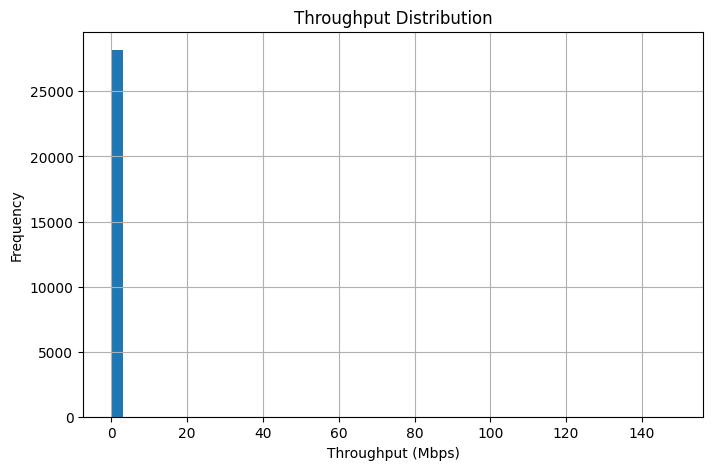

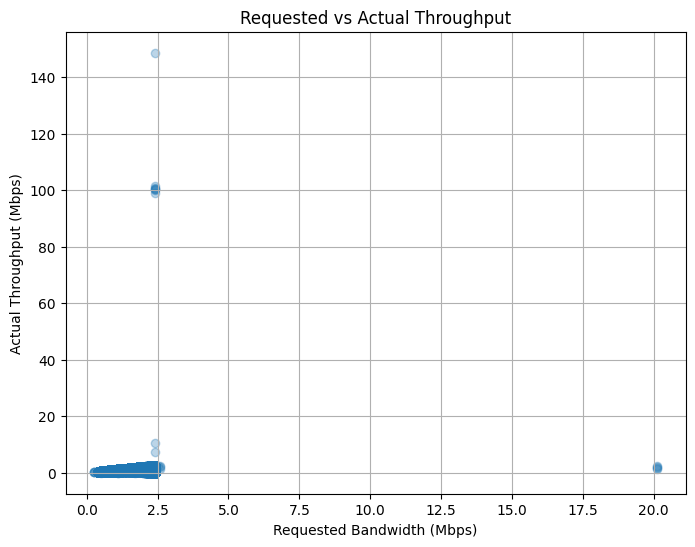

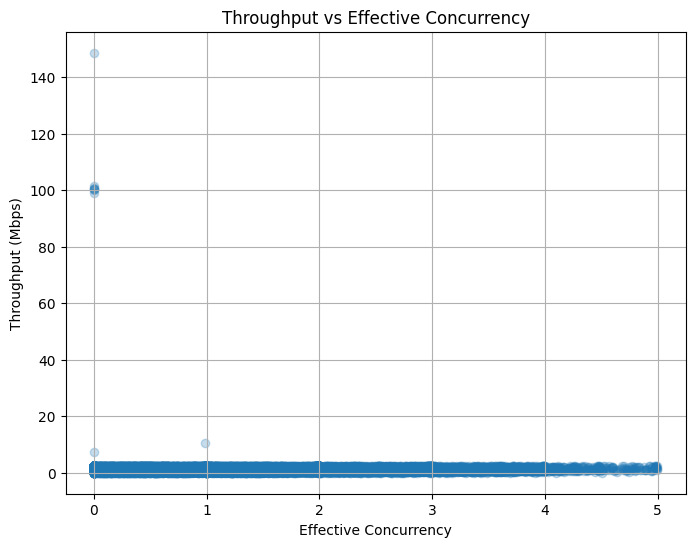

<Figure size 1000x600 with 0 Axes>

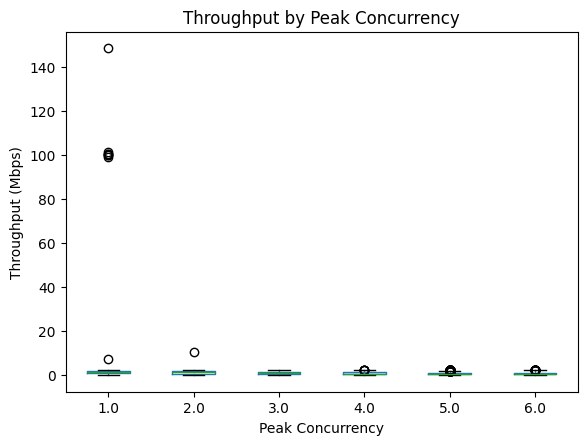

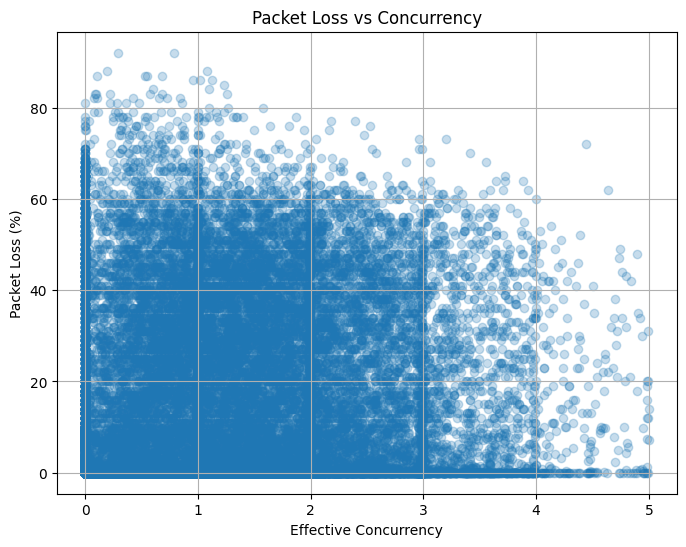

<Figure size 1000x600 with 0 Axes>

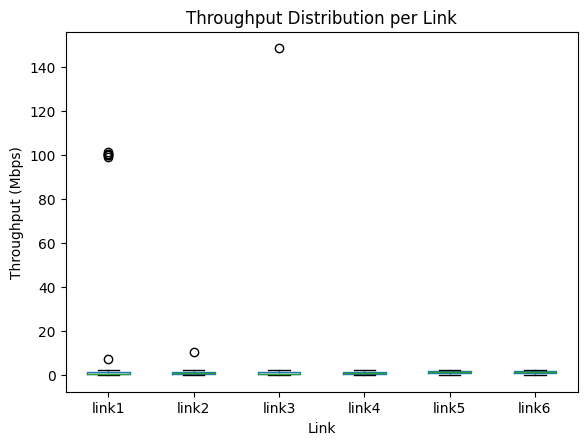

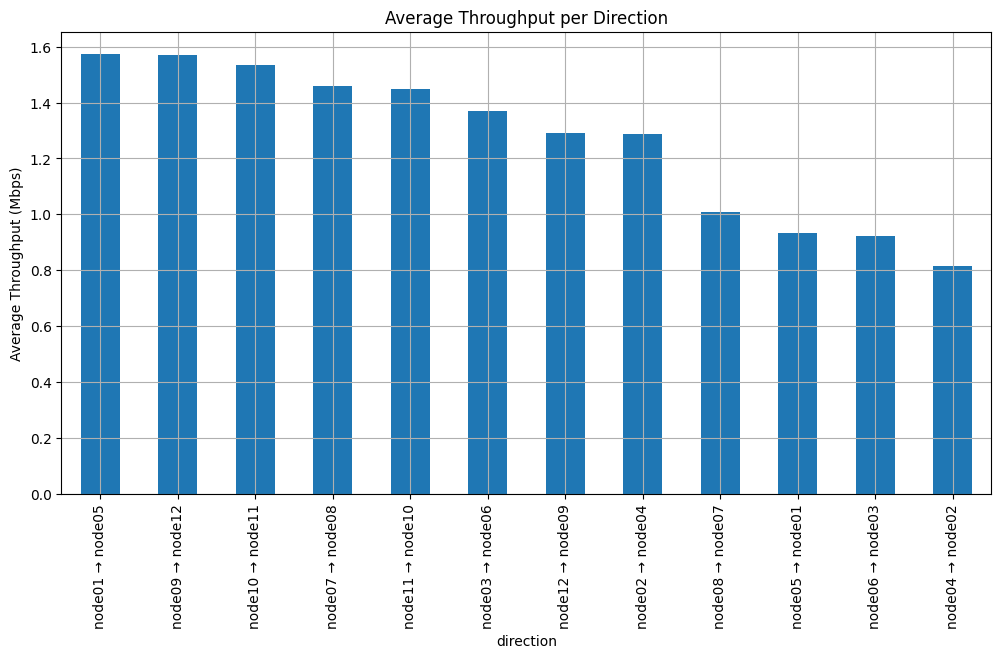

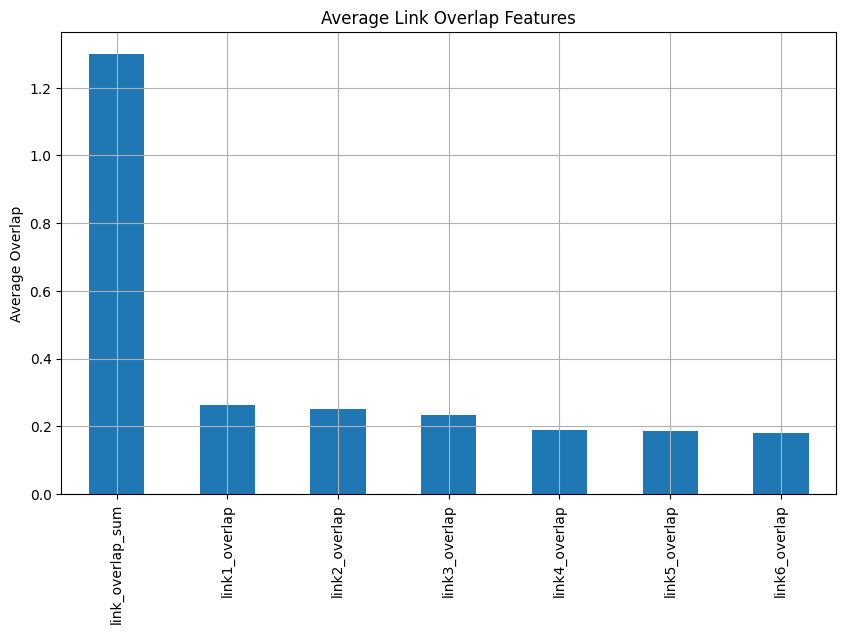

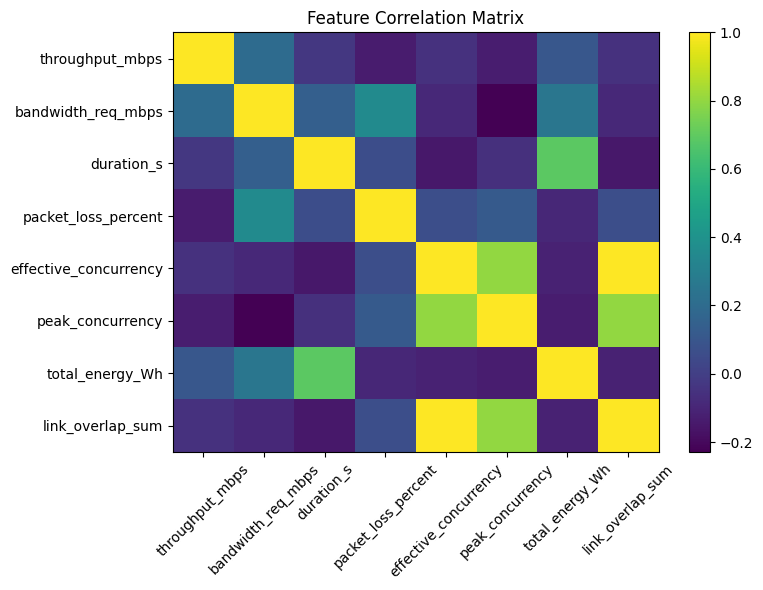

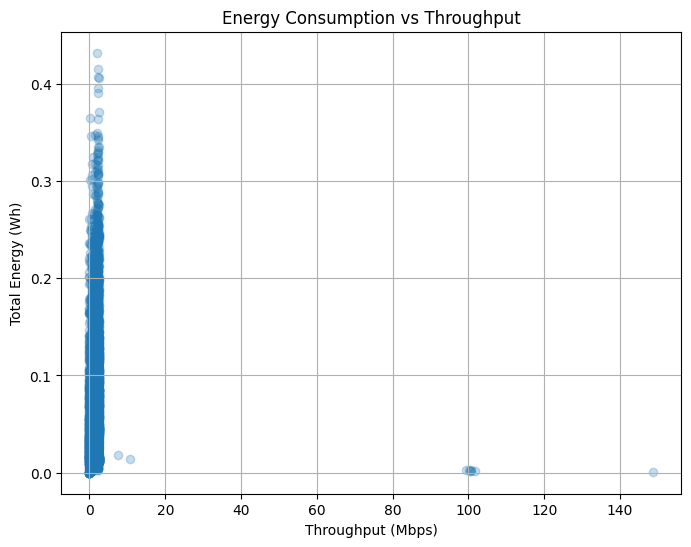

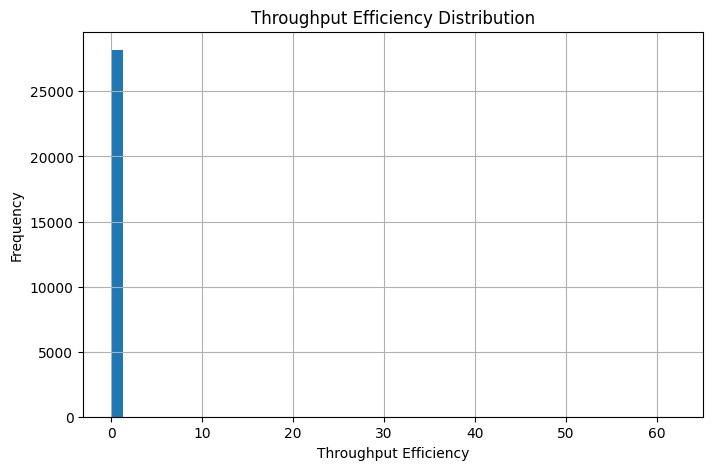

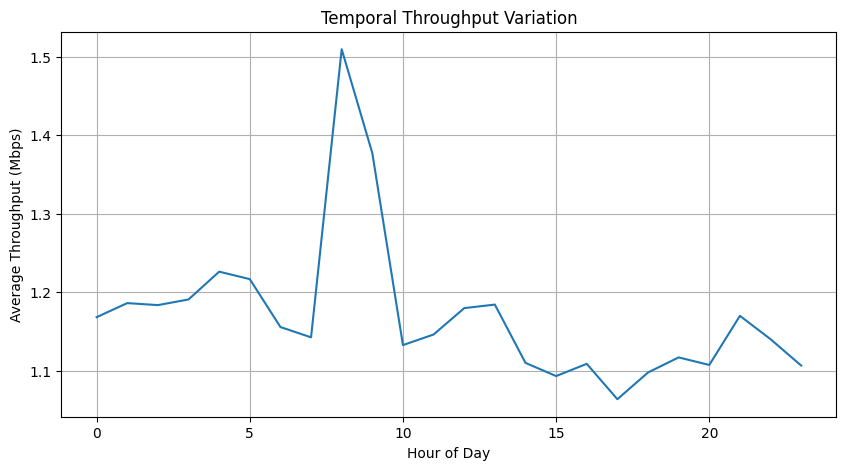


========== FAILURE RATE ==========

execution_failed
False    0.989036
True     0.010964
Name: proportion, dtype: float64

========== EDA COMPLETE ==========



In [107]:
# =========================================================
# EXPLORATORY DATA ANALYSIS (EDA)
# =========================================================

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------
# 1. CREATE EDA DATAFRAME
# ---------------------------------------------------------

df_eda = df_cc.copy()

# minimal cleanup only
df_eda = df_eda.replace([np.inf, -np.inf], np.nan)

print("\n========== DATASET INFO ==========\n")
print("Rows:", len(df_eda))
print("Columns:", len(df_eda.columns))

# =========================================================
# 2. DATASET CHARACTERISTICS
# =========================================================

print("\n========== BASIC STATISTICS ==========\n")

print(df_eda[[
    "throughput_mbps",
    "bandwidth_req_mbps",
    "duration_s",
    "packet_loss_percent",
    "effective_concurrency",
    "total_energy_Wh"
]].describe())

# =========================================================
# 3. THROUGHPUT DISTRIBUTION
# =========================================================

plt.figure(figsize=(8,5))

plt.hist(
    df_eda["throughput_mbps"],
    bins=50
)

plt.xlabel("Throughput (Mbps)")
plt.ylabel("Frequency")
plt.title("Throughput Distribution")

plt.grid(True)

plt.show()

# =========================================================
# 4. REQUESTED BANDWIDTH VS ACTUAL THROUGHPUT
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df_eda["bandwidth_req_mbps"],
    df_eda["throughput_mbps"],
    alpha=0.3
)

plt.xlabel("Requested Bandwidth (Mbps)")
plt.ylabel("Actual Throughput (Mbps)")
plt.title("Requested vs Actual Throughput")

plt.grid(True)

plt.show()

# =========================================================
# 5. THROUGHPUT VS EFFECTIVE CONCURRENCY
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df_eda["effective_concurrency"],
    df_eda["throughput_mbps"],
    alpha=0.25
)

plt.xlabel("Effective Concurrency")
plt.ylabel("Throughput (Mbps)")
plt.title("Throughput vs Effective Concurrency")

plt.grid(True)

plt.show()

# =========================================================
# 6. BOXPLOT BY PEAK CONCURRENCY
# =========================================================

plt.figure(figsize=(10,6))

df_eda.boxplot(
    column="throughput_mbps",
    by="peak_concurrency",
    grid=False
)

plt.title("Throughput by Peak Concurrency")
plt.suptitle("")

plt.xlabel("Peak Concurrency")
plt.ylabel("Throughput (Mbps)")

plt.show()

# =========================================================
# 7. PACKET LOSS VS CONCURRENCY
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df_eda["effective_concurrency"],
    df_eda["packet_loss_percent"],
    alpha=0.25
)

plt.xlabel("Effective Concurrency")
plt.ylabel("Packet Loss (%)")
plt.title("Packet Loss vs Concurrency")

plt.grid(True)

plt.show()

# =========================================================
# 8. THROUGHPUT PER LINK
# =========================================================

plt.figure(figsize=(10,6))

df_eda.boxplot(
    column="throughput_mbps",
    by="link_id",
    grid=False
)

plt.title("Throughput Distribution per Link")
plt.suptitle("")

plt.xlabel("Link")
plt.ylabel("Throughput (Mbps)")

plt.show()

# =========================================================
# 9. DIRECTIONAL ANALYSIS
# =========================================================

df_eda["direction"] = (
    df_eda["src_node"] + " → " + df_eda["dst_node"]
)

top_dirs = (
    df_eda.groupby("direction")["throughput_mbps"]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(12,6))

top_dirs.plot(kind="bar")

plt.ylabel("Average Throughput (Mbps)")
plt.title("Average Throughput per Direction")

plt.grid(True)

plt.show()

# =========================================================
# 10. OVERLAP FEATURE ANALYSIS
# =========================================================

overlap_cols = [
    c for c in df_eda.columns
    if "_overlap" in c
]

overlap_means = (
    df_eda[overlap_cols]
    .mean()
    .sort_values(ascending=False)
)

plt.figure(figsize=(10,6))

overlap_means.plot(kind="bar")

plt.ylabel("Average Overlap")
plt.title("Average Link Overlap Features")

plt.grid(True)

plt.show()

# =========================================================
# 11. CORRELATION MATRIX
# =========================================================

corr_features = [

    "throughput_mbps",
    "bandwidth_req_mbps",
    "duration_s",
    "packet_loss_percent",
    "effective_concurrency",
    "peak_concurrency",
    "total_energy_Wh",
    "link_overlap_sum"

]

corr = df_eda[corr_features].corr()

plt.figure(figsize=(8,6))

plt.imshow(corr, aspect="auto")

plt.colorbar()

plt.xticks(
    range(len(corr.columns)),
    corr.columns,
    rotation=45
)

plt.yticks(
    range(len(corr.columns)),
    corr.columns
)

plt.title("Feature Correlation Matrix")

plt.tight_layout()

plt.show()

# =========================================================
# 12. ENERGY VS THROUGHPUT
# =========================================================

plt.figure(figsize=(8,6))

plt.scatter(
    df_eda["throughput_mbps"],
    df_eda["total_energy_Wh"],
    alpha=0.25
)

plt.xlabel("Throughput (Mbps)")
plt.ylabel("Total Energy (Wh)")
plt.title("Energy Consumption vs Throughput")

plt.grid(True)

plt.show()

# =========================================================
# 13. THROUGHPUT EFFICIENCY
# =========================================================

df_eda["throughput_efficiency"] = (
    df_eda["throughput_mbps"] /
    df_eda["bandwidth_req_mbps"]
)

plt.figure(figsize=(8,5))

plt.hist(
    df_eda["throughput_efficiency"].dropna(),
    bins=50
)

plt.xlabel("Throughput Efficiency")
plt.ylabel("Frequency")
plt.title("Throughput Efficiency Distribution")

plt.grid(True)

plt.show()

# =========================================================
# 14. TEMPORAL EFFECTS
# =========================================================

hourly_tp = (
    df_eda.groupby("hour")["throughput_mbps"]
    .mean()
)

plt.figure(figsize=(10,5))

hourly_tp.plot()

plt.xlabel("Hour of Day")
plt.ylabel("Average Throughput (Mbps)")
plt.title("Temporal Throughput Variation")

plt.grid(True)

plt.show()

# =========================================================
# 15. FAILED EXECUTION ANALYSIS
# =========================================================

fail_rate = (
    df_eda["execution_failed"]
    .value_counts(normalize=True)
)

print("\n========== FAILURE RATE ==========\n")
print(fail_rate)

# =========================================================
# 16. SUMMARY OBSERVATIONS
# =========================================================

print("\n========== EDA COMPLETE ==========\n")


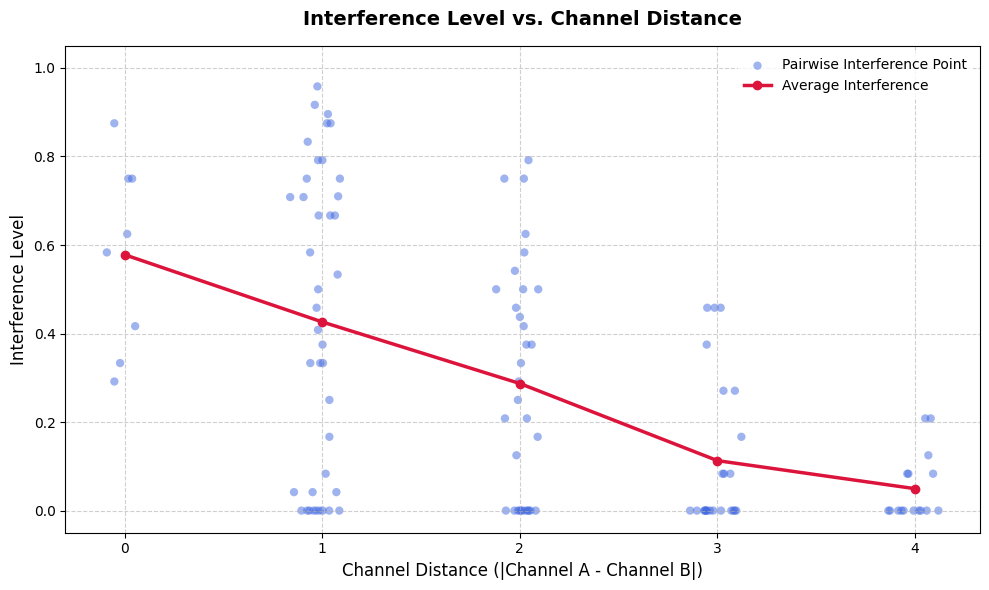

In [1]:
import matplotlib.pyplot as plt
import numpy as np

# 1. Define the interference matrix provided
INTERFERENCE_MATRIX = {
    (("link1", "downlink"), ("link2", "downlink")): {"link1": 0.875, "link2": 0.875},
    (("link1", "downlink"), ("link2", "uplink")): {"link1": 0.0417, "link2": 0.9167},
    (("link1", "downlink"), ("link3", "downlink")): {"link1": 0.5, "link3": 0.5},
    (("link1", "downlink"), ("link3", "uplink")): {"link1": 0.4583, "link3": 0.5417},
    (("link1", "downlink"), ("link4", "downlink")): {"link1": 0.0, "link4": 0.0},
    (("link1", "downlink"), ("link4", "uplink")): {"link1": 0.0, "link4": 0.0},
    (("link1", "downlink"), ("link5", "downlink")): {"link1": 0.0, "link5": 0.0},
    (("link1", "downlink"), ("link5", "uplink")): {"link1": 0.0, "link5": 0.0},
    (("link1", "downlink"), ("link6", "downlink")): {"link1": 0.75, "link6": 0.875},
    (("link1", "downlink"), ("link6", "uplink")): {"link1": 0.5833, "link6": 0.3333},
    (("link1", "uplink"), ("link2", "downlink")): {"link1": 0.9583, "link2": 0.75},
    (("link1", "uplink"), ("link2", "uplink")): {"link1": 0.8958, "link2": 0.7917},
    (("link1", "uplink"), ("link3", "downlink")): {"link1": 0.75, "link3": 0.375},
    (("link1", "uplink"), ("link3", "uplink")): {"link1": 0.75, "link3": 0.375},
    (("link1", "uplink"), ("link4", "downlink")): {"link1": 0.0833, "link4": 0.0},
    (("link1", "uplink"), ("link4", "uplink")): {"link1": 0.0833, "link4": 0.0},
    (("link1", "uplink"), ("link5", "downlink")): {"link1": 0.0833, "link5": 0.0},
    (("link1", "uplink"), ("link5", "uplink")): {"link1": 0.0833, "link5": 0.0},
    (("link1", "uplink"), ("link6", "downlink")): {"link1": 0.4167, "link6": 0.75},
    (("link1", "uplink"), ("link6", "uplink")): {"link1": 0.625, "link6": 0.2917},
    (("link2", "downlink"), ("link3", "downlink")): {"link2": 0.7917, "link3": 0.4083},
    (("link2", "downlink"), ("link3", "uplink")): {"link2": 0.7083, "link3": 0.4583},
    (("link2", "downlink"), ("link4", "downlink")): {"link2": 0.3333, "link4": 0.2917},
    (("link2", "downlink"), ("link4", "uplink")): {"link2": 0.4375, "link4": 0.7917},
    (("link2", "downlink"), ("link5", "downlink")): {"link2": 0.2708, "link5": 0.0},
    (("link2", "downlink"), ("link5", "uplink")): {"link2": 0.2708, "link5": 0.0},
    (("link2", "downlink"), ("link6", "downlink")): {"link2": 0.25, "link6": 0.0},
    (("link2", "downlink"), ("link6", "uplink")): {"link2": 0.71, "link6": 0.0},
    (("link2", "uplink"), ("link3", "downlink")): {"link2": 0.8333, "link3": 0.3333},
    (("link2", "uplink"), ("link3", "uplink")): {"link2": 0.5, "link3": 0.6667},
    (("link2", "uplink"), ("link4", "downlink")): {"link2": 0.5833, "link4": 0.4167},
    (("link2", "uplink"), ("link4", "uplink")): {"link2": 0.625, "link4": 0.5},
    (("link2", "uplink"), ("link5", "downlink")): {"link2": 0.375, "link5": 0.0},
    (("link2", "uplink"), ("link5", "uplink")): {"link2": 0.4583, "link5": 0.0},
    (("link2", "uplink"), ("link6", "downlink")): {"link2": 0.75, "link6": 0.0},
    (("link2", "uplink"), ("link6", "uplink")): {"link2": 0.6667, "link6": 0.0833},
    (("link3", "downlink"), ("link4", "downlink")): {"link3": 0.0, "link4": 0.0},
    (("link3", "downlink"), ("link4", "uplink")): {"link3": 0.0417, "link4": 0.0417},
    (("link3", "downlink"), ("link5", "downlink")): {"link3": 0.0, "link5": 0.0},
    (("link3", "downlink"), ("link5", "uplink")): {"link3": 0.0, "link5": 0.0},
    (("link3", "downlink"), ("link6", "downlink")): {"link3": 0.1667, "link6": 0.0},
    (("link3", "downlink"), ("link6", "uplink")): {"link3": 0.25, "link6": 0.0},
    (("link3", "uplink"), ("link4", "downlink")): {"link3": 0.1667, "link4": 0.0},
    (("link3", "uplink"), ("link4", "uplink")): {"link3": 0.375, "link4": 0.0},
    (("link3", "uplink"), ("link5", "downlink")): {"link3": 0.2083, "link5": 0.0},
    (("link3", "uplink"), ("link5", "uplink")): {"link3": 0.0, "link5": 0.0},
    (("link3", "uplink"), ("link6", "downlink")): {"link3": 0.2083, "link6": 0.0},
    (("link3", "uplink"), ("link6", "uplink")): {"link3": 0.125, "link6": 0.0},
    (("link4", "downlink"), ("link5", "downlink")): {"link4": 0.6667, "link5": 0.3333},
    (("link4", "downlink"), ("link5", "uplink")): {"link4": 0.7083, "link5": 0.5333},
    (("link4", "downlink"), ("link6", "downlink")): {"link4": 0.0, "link6": 0.0},
    (("link4", "downlink"), ("link6", "uplink")): {"link4": 0.4583, "link6": 0.4583},
    (("link4", "uplink"), ("link5", "downlink")): {"link4": 0.3333, "link5": 0.5833},
    (("link4", "uplink"), ("link5", "uplink")): {"link4": 0.0, "link5": 0.0},
    (("link4", "uplink"), ("link6", "downlink")): {"link4": 0.0, "link6": 0.0},
    (("link4", "uplink"), ("link6", "uplink")): {"link4": 0.1667, "link6": 0.0833},
    (("link5", "downlink"), ("link6", "downlink")): {"link5": 0.2083, "link6": 0.125},
    (("link5", "downlink"), ("link6", "uplink")): {"link5": 0.0, "link6": 0.0},
    (("link5", "uplink"), ("link6", "downlink")): {"link5": 0.2083, "link6": 0.0833},
    (("link5", "uplink"), ("link6", "uplink")): {"link5": 0.0, "link6": 0.0},
}

# 2. Map links to their respective channels
link_channels = {
    "link1": 1,
    "link2": 2,
    "link3": 3,
    "link4": 4,
    "link5": 5,
    "link6": 1,  # Co-channel with link1 (distance = 0)
}

# 3. Extract distances and interference values
distances = []
interferences = []

for ((linkA, dirA), (linkB, dirB)), values in INTERFERENCE_MATRIX.items():
    # Calculate absolute channel distance
    chA = link_channels[linkA]
    chB = link_channels[linkB]
    dist = abs(chA - chB)
    
    # Collect the individual interference value for each link in the pair
    distances.append(dist)
    interferences.append(values[linkA])
    
    distances.append(dist)
    interferences.append(values[linkB])

# Convert to numpy arrays for easier manipulation
distances = np.array(distances)
interferences = np.array(interferences)

# Calculate mean interference per distance step for the trendline
unique_distances = np.unique(distances)
mean_interferences = [np.mean(interferences[distances == d]) for d in unique_distances]

# 4. Plotting
plt.figure(figsize=(10, 6))

# Add slight jitter to the X-axis (distances) so overlapping points are visible
jittered_distances = distances + np.random.normal(0, 0.06, size=len(distances))

# Scatter plot of raw data points
plt.scatter(jittered_distances, interferences, alpha=0.5, color='royalblue', edgecolors='none', label='Pairwise Interference Point')

# Plot the average trendline
plt.plot(unique_distances, mean_interferences, color='crimson', marker='o', linewidth=2.5, label='Average Interference')

# Labels and styling
plt.title("Interference Level vs. Channel Distance", fontsize=14, fontweight='bold', pad=15)
plt.xlabel("Channel Distance (|Channel A - Channel B|)", fontsize=12)
plt.ylabel("Interference Level", fontsize=12)
plt.xticks(unique_distances)
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend(frameon=True, facecolor='white', edgecolor='none')
plt.ylim(-0.05, 1.05)

# Show plot
plt.tight_layout()
plt.show()